
---
## Projet — Option avec sauts (modèle de Merton)

##Modèle de Merton
Le modèle de Merton étend la dynamique de Black–Scholes en ajoutant des sauts au processus. La dynamique du prix $S_t$ est donnée par:
$$
dS_t = \underbrace{S_t \,\nu\, dt}_{\text{Tendance}}
      + \underbrace{S_t \,\sigma\, dB_t}_{\text{Diffusion}}
      + \underbrace{S_t\,(\eta - 1)\, dq_t}_{\text{Sauts}}
$$


La différence essentielle avec le modèle de Black–Scholes est l’ajout du terme de saut
$$
S_t(\eta - 1)\,dq_t
$$
qui permet au prix de subir un déplacement instantané (un « bond ») lorsque survient un événement de saut.

$dq$ (Processus de Poisson) : C'est le déclencheur. Il vaut 0 la plupart du temps, et vaut 1 quand un événement rare ("saut") se produit. La fréquence de ces sauts est régie par le paramètre d'intensité $\lambda$.

$(\eta - 1)$ (Amplitude) : Si un saut se produit ($dq=1$), le prix de l'actif $S$ est instantanément multiplié par une variable aléatoire positive $\eta$.

On considère le prix $V(t,s)$ d’une option européenne de payoff général $\varphi$ sur un
actif $S_t$ suivant le modèle de diffusion avec sauts (modèle de Merton) :

$$
dS_t = S_t\big( \mu\,dt + \sigma\,dB_t + (\eta-1)\,dq_t \big),
$$

où $dq_t$ est un processus de Poisson de paramètre $\lambda > 0$, et où $\eta>0$ représente
l’amplitude relative des sauts.
La valeur $V(t,s)$  correspondant à une option de payoff sur l’actif S
satisfait l’EDP :

$$
-\,\partial_t V(t,s)
- \tfrac12 \sigma^2 s^2 \,\partial_{ss} V(t,s)
- (r - \lambda \kappa)\,s\,\partial_s V(t,s)+ r\,V(t,s)+ L(V)(s)= 0,\quad s>0,\ 0<t<T,
$$

avec condition terminale générale

$$
V(T,s) = \varphi(s).
$$

On a noté $V \mapsto L(V)$ l’opérateur linéaire défini par :

$$
L(V)(s)
:= \lambda\Big(
  V(s)
  - \int_0^{\infty} V(s \eta)\,g(\eta)\,d\eta
\Big),
$$

où $g : \mathbb{R} \to \mathbb{R}_+$ est une densité de l’amplitude du saut $\eta$ telle que

$$
g(\eta) \ge 0,\qquad \int_0^\infty g(\eta)\,d\eta = 1,
$$

et où

$$
\kappa := \mathbb{E}[\eta-1] = \int_0^\infty (\eta-1)\,g(\eta)\,d\eta.
$$

Les paramètres de marché ($r$, $\sigma$, $\lambda$, $g$) sont constants.


---

Ce notebook implémente les **Questions 1 à 5** du projet :
- **Q1** : Comportement près de S=0
- **Q2** : Changement de variable s = Ke^x
- **Q3** : Discrétisation du terme intégral
- **Q4** : Schémas explicites (Upwind et DFC)
- **Q5** : Comparaison avec formule de Merton analytique et modèle sans saut
- **Q6** : Schémas implicite

---


## Imports et Configuration

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import splu
from scipy.stats import norm
from scipy.special import factorial
from math import log, sqrt, exp
import time
import math as mt

# Configuration des graphiques
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

---
# Partie 1 : Théorie
---

## Question 1 — Condition au voisinage de $S=0$

On pose, au voisinage de $S=0$,
$$
v(t,S) = a(t) S + b(t),
$$
où $a(t)$ et $b(t)$ sont des fonctions à déterminer.

On identifie $v(t,S)$ et $V(t,S)$ dans l’EDP :

$$
- v_t
- \tfrac12 \sigma^2 S^2 v_{SS}
- (r - \lambda\kappa) S v_S
+ r v
+ L(v)(S)
= 0.
$$

### Dérivées de $v$

On a :
$$
v_t(t,S) = a'(t) S + b'(t),\qquad
v_S(t,S) = a(t),\qquad
v_{SS}(t,S) = 0.
$$

### Terme intégral $L(v)$

Par définition :
$$
L(v)(S)
= \lambda\Big(
  v(t,S)
  - \int_0^\infty v(t,S\eta)\,g(\eta)\,d\eta
\Big).
$$

Or
$$
v(t,S\eta) = a(t) S\eta + b(t),
$$

donc
$$
\int_0^\infty v(t,S\eta)\,g(\eta)\,d\eta
= a(t) S \int_0^\infty \eta g(\eta)\,d\eta
+ b(t) \int_0^\infty g(\eta)\,d\eta.
$$

On utilise :
$$
\int_0^\infty g(\eta)\,d\eta = 1,
\qquad
\int_0^\infty \eta g(\eta)\,d\eta = 1+\kappa.
$$

Donc
$$
\int_0^\infty v(t,S\eta)\,g(\eta)\,d\eta
= a(t) S (1+\kappa) + b(t).
$$

Ainsi :
$$
\begin{aligned}
L(v)(S)
&= \lambda\Big(
  a(t)S + b(t) - \big(a(t)S(1+\kappa)+b(t)\big)
\Big) \\
&= \lambda\big(-\kappa a(t) S\big)
= -\lambda\kappa a(t) S.
\end{aligned}
$$

### Substitution dans l’EDP

On remplace tout dans :

$$
- v_t
- \tfrac12 \sigma^2 S^2 v_{SS}
- (r - \lambda\kappa) S v_S
+ r v
+ L(v)
= 0.
$$

En détail :

- $v_t = a'(t)S + b'(t)$
- $v_{SS} = 0$
- $v_S = a(t)$
- $v = a(t)S + b(t)$
- $L(v) = -\lambda\kappa a(t) S$

On obtient :
$$
\begin{aligned}
0
&= -\big(a'(t)S + b'(t)\big)
- (r-\lambda\kappa)S a(t)
+ r\big(a(t)S + b(t)\big)
- \lambda\kappa a(t) S.
\end{aligned}
$$

On regroupe :

- Terme en $S$ :
  $$
  -a'(t)S
  - (r-\lambda\kappa)a(t)S
  + r a(t) S
  - \lambda\kappa a(t) S
  = -a'(t) S,
  $$
  car les termes en $a(t)S$ se compensent.

- Terme constant :
  $$
  -b'(t) + r b(t)=0.
  $$

Donc, pour tout $S$ proche de $0$ :

$$
-a'(t) S - b'(t) + r b(t) = 0.
$$

Comme cette égalité est vraie pour tout $S$, on obtient le système :

$$
a'(t) = 0,
\qquad
b'(t) = r b(t).
$$

### Utilisation de la condition terminale

On a la condition terminale générale :
$$
V(T,S) = \varphi(S).
$$

Son développement au voisinage de $S=0$ est :
$$
\varphi(S)
\simeq \varphi(0) + \varphi'(0)\,S.
$$

En identifiant avec $v(T,S)=a(T)S + b(T)$, on obtient :
$$
a(T) = \varphi'(0),\qquad
b(T) = \varphi(0).
$$

Les solutions des EDO sont :
$$
a(t) = \varphi'(0),
\qquad
b(t) = \varphi(0)\,e^{-r(T-t)}.
$$

### Condition de bord gauche

Au voisinage de $S=0$, on retient donc la condition limite :

$$
v(t,S) \approx a(t)S + b(t)
= \varphi'(0) S + \varphi(0)\,e^{-r(T-t)}.
$$

Ce sera la condition au bord gauche pour l’EDP en $S$.

### Condition de bord droite

Au voisinage de $S=\infty$, on retient la condition limite :

$$
v(t,S) \approx 0
$$

Ce sera la condition au bord droit pour l’EDP en $S$.


## Question 2 — Passage en forward puis changement de variable logarithmique



On part de l’équation de $V(t,s)$ donnée dans l’énoncé :

$$
- \partial_t V(t,s)
- \frac{1}{2}\sigma^2 s^2 \partial_{ss} V(t,s)
- (r - \lambda \kappa)\,s\,\partial_s V(t,s)
+ r\,V(t,s)
+ L(V)(s)
= 0,
$$

avec

$$
L(V)(s)
= \lambda\Big(
  V(t,s)
  - \int_0^\infty V(t,s h)\,g(h)\,dh
\Big),
$$

et la condition terminale générale

$$
V(T,s) = \varphi(s).
$$

### 2.1 Passage en variable forward

On définit la fonction **forward** :

$$
u(t,s) := V(T - t, s), \qquad 0 \le t \le T.
$$

On a alors les relations :

$$
\partial_t u(t,s) = -\partial_t V(T - t,s),
\qquad
\partial_s u(t,s) = \partial_s V(T - t,s),
\qquad
\partial_{ss} u(t,s) = \partial_{ss} V(T - t,s).
$$

En remplaçant $t' = T - t$ dans l’EDP de $V$ :

$$
- \partial_{t'} V(t',s)
- \frac{1}{2}\sigma^2 s^2 \partial_{ss} V(t',s)
- (r - \lambda \kappa)\,s\,\partial_s V(t',s)
+ r\,V(t',s)
+ L(V)(t',s)
= 0.
$$

En particulier, pour $t' = T - t$ :

$$
- \partial_t V(T - t,s)
- \frac{1}{2}\sigma^2 s^2 \partial_{ss} V(T - t,s)
- (r - \lambda \kappa)\,s\,\partial_s V(T - t,s)
+ r\,V(T - t,s)
+ L(V)(T - t,s)
= 0.
$$

En termes de $u$ :

$$
\begin{aligned}
- \partial_t V(T - t,s) &= \partial_t u(t,s), \\
\partial_s V(T - t,s) &= \partial_s u(t,s), \\
\partial_{ss} V(T - t,s) &= \partial_{ss} u(t,s), \\
V(T - t,s) &= u(t,s), \\
L(V)(T - t,s) &= L(u)(t,s).
\end{aligned}
$$

On obtient donc l’EDP **forward** pour $u(t,s)$ :

$$
u_t(t,s)
- \frac{1}{2}\sigma^2 s^2 u_{ss}(t,s)
- (r - \lambda \kappa)\,s\,u_s(t,s)
+ r\,u(t,s)
+ L(u)(t,s)
= 0,
$$

c’est-à-dire

$$
u_t
- \frac{1}{2}\sigma^2 s^2 u_{ss}
- (r - \lambda \kappa)\,s\,u_s
+ r\,u
+ \lambda\Big(
  u
  - \int_0^\infty u(t,s \eta)\,g(\eta)\,d\eta
\Big)
= 0.
$$

On regroupe $r u + \lambda u = (r+\lambda)u$ et on obtient :

$$
\boxed{
u_t
- \frac{1}{2}\sigma^2 s^2 u_{ss}
- (r - \lambda \kappa)\,s\,u_s
+ (r+\lambda)\,u
- \lambda\int_0^\infty u(t,s \eta)\,g(\eta)\,d\eta
= 0.
}
$$

La condition **initiale** forward est

$$
u(0,s) = V(T,s) = \varphi(s).
$$

La condition de bord gauche obtenue en Question 1 (au voisinage de $s=0$) est

$$
u(t,s) \approx \varphi'(0)\,s + \varphi(0)\,e^{-rt},
\qquad
u(t,0) = \varphi(0)e^{-rt}.
$$

---

### 2.2 Changement de variable logarithmique $s = K e^x$

On introduit la variable

$$
s = K e^x,
\qquad
x = \log(s/K),
$$

et l’on considère la **même fonction forward** $u$ exprimée en $x$ :

$$
u(t,x) := u(t,s) \quad \text{avec } s = K e^x.
$$

On a

$$
\frac{\partial s}{\partial x} = s = K e^x.
$$

Par la chaîne :

$$
u_t(t,x) = u_t(t,s),
$$

$$
u_x(t,x) = u_s(t,s)\,\frac{\partial s}{\partial x}
= s\,u_s(t,s),
$$

$$
u_{xx}(t,x)
= \partial_x\big(s\,u_s(t,s)\big)
= s\,u_s(t,s) + s^2 u_{ss}(t,s).
$$

On en déduit

$$
s\,u_s = u_x,
\qquad
s^2 u_{ss} = u_{xx} - u_x.
$$

Pour le terme intégral :

$$
\int_0^\infty u(t,s \eta)\,g(\eta)\,d\eta
= \int_0^\infty u\big(t, K e^x \eta\big)\,g(\eta)\,d\eta
= \int_0^\infty u\big(t, x + \log \eta\big)\,g(\eta)\,d\eta.
$$

En remplaçant dans l’EDP forward en $(t,s)$ :

$$
u_t
- \frac{1}{2}\sigma^2 (u_{xx} - u_x)
- (r - \lambda \kappa) u_x
+ (r+\lambda)u
- \lambda\int_0^\infty u(t,x+\log \eta)\,g(\eta)\,d\eta
= 0.
$$

On regroupe les termes en $u_{xx}$, $u_x$ et $u$ :

- terme en $u_{xx}$ :
  $$
  -\frac12\sigma^2 u_{xx},
  $$
- terme en $u_x$ :
  $$
  +\frac12\sigma^2 u_x - (r-\lambda\kappa)u_x
  = \Big(\frac12\sigma^2 - r + \lambda\kappa\Big) u_x,
  $$
- terme en $u$ :
  $$
  (r+\lambda)u.
  $$

On pose

$$
\beta := \frac12\sigma^2 - r + \lambda\kappa,
\qquad
\delta := r + \lambda.
$$

L’EDP forward en $(t,x)$ devient

$$
\boxed{
u_t
- \frac12\sigma^2 u_{xx}
+ \beta\,u_x
+ \delta\,u
- \lambda\int_0^\infty u(t,x+\log \eta)\,g(\eta)\,d\eta
= 0.
}
$$

On travaille sur un intervalle tronqué

$$
x \in [X_{\min}, X_{\max}],
\qquad
X_{\min} := \log(S_{\min}/K),\quad
X_{\max} := \log(S_{\max}/K),
$$

avec les conditions aux limites (tirées de la Question 1 et de l’énoncé) :

- à gauche :

$$
u_g(t,x) = a(t) K e^x + b(t)
= \varphi'(0)\,K e^x + \varphi(0) e^{-rt},
\qquad x \le X_{\min},
$$

- à droite :

$$
u_d(t,x) = 0,
\qquad x \ge X_{\max}.
$$

La condition initiale forward en $x$ est

$$
u(0,x) = \varphi(K e^x).
$$



## Question 3 — Discrétisation du terme intégral pour $u(t,x)$

On considère le terme non local

$$
I[u](t,x) := \int_0^\infty u(t,x+\log \eta)\,g(\eta)\,d\eta.
$$

On effectue le changement de variable

$$
y = \log \eta
\quad\Longrightarrow\quad
\eta = e^y, \; d\eta = e^y dy,
$$

et on obtient

$$
I[u](t,x)
= \int_{-\infty}^{+\infty}
u(t,x+y)\,g(e^y)\,e^y\,dy.
$$

### Maillage en $x$

On introduit un maillage uniforme sur $[X_{\min}, X_{\max}]$ :

$$
x_i = X_{\min} + i h,
\qquad i = 0,1,\dots,I+1,
$$

avec pas

$$
h = \frac{X_{\max} - X_{\min}}{I+1}.
$$

Les points intérieurs sont $i = 1,\dots,I$ et les indices $i=0$ et $i=I+1$ correspondent aux
bords (valeurs imposées par $u_g$ et $u_d$).

On note

$$
U_i^j \approx u(t_j,x_i),
\qquad t_j = j k.
$$

### Discrétisation de l’intégrale

On choisit un entier $P \ge 1$ et on discrétise $y$ sur les multiples de $h$ :

$$
y_m = x_m,
\qquad
m = -P,\dots,P.
$$


On définit les poids **en fonction de $x_m$** :

$$
w_m := g(e^{x_m})\,e^{x_m}.
$$

L’intégrale est alors approchée par une somme de type Riemann :

$$
I[u](t_j,x_i)
\approx h \sum_{m=-P}^{P} w_m\,u(t_j, x_i + x_m).
$$

on peut approximer par :

$$
\boxed{
I[u](t_j,x_i)
\approx h \sum_{m=-P}^{P} w_m\,U_{i+m}^j.
}
$$

### Gestion des indices hors domaine

Lorsque $i+m \notin \{1,\dots,I\}$, on utilise les conditions aux limites :

- si $i+m \le 0$ : $U_{i+m}^j$ est remplacé par $u_g(t_j,x_{i+m})$,
- si $i+m \ge I+1$ : $U_{i+m}^j$ est remplacé par $u_d(t_j,x_{i+m})$.

Ces contributions sont réunies dans un **vecteur de bord** $b^{j,\mathrm{int}}$.

### Matrice de convolution

On peut définir une matrice $W \in \mathbb{R}^{I\times I}$ telle que, pour

$$
U^j =
\begin{pmatrix}
U_1^j \\ \vdots \\ U_I^j
\end{pmatrix},
$$

on ait

$$
(W U^j)_i
= h \sum_{\substack{m=-P\\1\le i+m\le I}}^{P} w_m\,U_{i+m}^j.
$$

Les coefficients de $W$ sont donc

$$
W_{i,k} =
\begin{cases}
h\,w_{k-i}, & \text{si } k-i \in \{-P,\dots,P\}, \\
0, & \text{sinon}.
\end{cases}
$$

Les contributions venant des indices $i+m \notin \{1,\dots,I\}$ sont incorporées dans
$b^{j,\mathrm{int}}$ de sorte que

$$
I[u](t_j,x_i)
\approx (W U^j)_i + b^{j,\mathrm{int}}_i.
$$

---

## Question 4 — Schéma explicite aux différences finies pour $u(t,x)$


On part de l’EDP forward en $(t,x)$ :

$$
u_t
- \frac12\sigma^2 u_{xx}
+ \beta\,u_x
+ \delta\,u
- \lambda I[u]
= 0,
$$

avec

$$
\beta = \frac12\sigma^2 - r + \lambda\kappa,
\qquad
\delta = r + \lambda,
$$

et

$$
I[u](t_j,x_i) \approx h \sum_{m=-P}^{P} w_m U_{i+m}^j.
$$

### Maillage en temps et en espace

Temps :

$$
t_j = j k,
\qquad
j = 0,1,\dots,J+1,
\qquad
k = \frac{T}{J+1}.
$$

Espace :

$$
x_i = X_{\min} + i h,
\qquad
i = 0,1,\dots,I+1.
$$

Les inconnues sont $U_i^j \approx u(t_j,x_i)$ pour $i=1,\dots,I$.

### Approximation des dérivées

Temps (Euler explicite) :

$$
u_t(t_j,x_i)
\approx \frac{U_i^{j+1} - U_i^j}{k}.
$$

Diffusion :

$$
u_{xx}(t_j,x_i)
\approx \frac{U_{i+1}^j - 2 U_i^j + U_{i-1}^j}{h^2}.
$$

Terme intégral :

$$
I[u](t_j,x_i)
\approx h \sum_{m=-P}^{P} w_m U_{i+m}^j.
$$

---

### 4.1 Schéma explicite upwind (cas $\beta > 0$)

Pour la dérivée première, si $\beta > 0$, on utilise un schéma upwind arrière :

$$
u_x(t_j,x_i)
\approx \frac{U_i^j - U_{i-1}^j}{h}.
$$

En remplaçant dans l’EDP :

$$
\frac{U_i^{j+1} - U_i^j}{k}
- \frac12\sigma^2
\frac{U_{i+1}^j - 2U_i^j + U_{i-1}^j}{h^2}
+ \beta \frac{U_i^j - U_{i-1}^j}{h}
+ \delta U_i^j
- \lambda h \sum_{m=-P}^{P} w_m U_{i+m}^j
= 0.
$$

On isole $U_i^{j+1}$ :

$$
\begin{aligned}
U_i^{j+1}
&= U_i^j
+ k\Bigg[
\frac12\sigma^2
\frac{U_{i+1}^j - 2U_i^j + U_{i-1}^j}{h^2}
- \beta \frac{U_i^j - U_{i-1}^j}{h}
- \delta U_i^j \\
&\qquad\qquad\qquad
+ \lambda h \sum_{m=-P}^{P} w_m U_{i+m}^j
\Bigg].
\end{aligned}
$$

En regroupant les coefficients devant $U_{i-1}^j$, $U_i^j$ et $U_{i-1}^j$ :

- coefficient de $U_{i-1}^j$ :

$$
a = k\left(
\frac{\sigma^2}{2h^2}
+ \frac{\beta}{h}
\right),
$$

- coefficient de $U_i^j$ :

$$
b = 1 - k\left(
\frac{\sigma^2}{h^2}
+ \frac{\beta}{h}
+ \delta
\right),
$$

- coefficient de $U_{i+1}^j$ :

$$
c = k\,\frac{\sigma^2}{2h^2}.
$$

Le schéma scalaire s’écrit donc, pour $i=1,\dots,I$ :

$$
\boxed{
U_i^{j+1}
= a\,U_{i-1}^j
+ b\,U_i^j
+ c\,U_{i+1}^j
+ \lambda k h \sum_{m=-P}^{P} w_m U_{i+m}^j.
}
$$

Pour $i=1$ et $i=I$, les termes faisant intervenir $U_0^j$ ou $U_{I+1}^j$ sont remplacés par les
conditions aux limites $u_g$ et $u_d$ et envoyés dans un **vecteur de bord**.

---

### 4.2 Schéma explicite centré (DFC)

Pour un schéma centré sur $u_x$ :

$$
u_x(t_j,x_i)
\approx \frac{U_{i+1}^j - U_{i-1}^j}{2h}.
$$

En remplaçant dans l’EDP :

$$
\frac{U_i^{j+1} - U_i^j}{k}
- \frac12\sigma^2
\frac{U_{i+1}^j - 2U_i^j + U_{i-1}^j}{h^2}
+ \beta \frac{U_{i+1}^j - U_{i-1}^j}{2h}
+ \delta U_i^j
- \lambda h \sum_{m=-P}^{P} w_m U_{i+m}^j
= 0.
$$

On isole $U_i^{j+1}$ et on regroupe :

- coefficient de $U_{i-1}^j$ :

$$
\tilde a = k\left(
\frac{\sigma^2}{2h^2}
+ \frac{\beta}{2h}
\right),
$$

- coefficient de $U_i^j$ :

$$
\tilde b = 1 - k\left(
\frac{\sigma^2}{h^2}
+ \delta
\right),
$$

- coefficient de $U_{i+1}^j$ :

$$
\tilde c = k\left(
\frac{\sigma^2}{2h^2}
- \frac{\beta}{2h}
\right).
$$

Le schéma s’écrit alors :

$$
\boxed{
U_i^{j+1}
= \tilde a\,U_{i-1}^j
+ \tilde b\,U_i^j
+ \tilde c\,U_{i+1}^j
+ \lambda k h \sum_{m=-P}^{P} w_m U_{i+m}^j.
}
$$

Comme pour le schéma upwind, les indices hors $\{1,\dots,I\}$ (i.e. $i+m\le 0$ ou $i+m\ge I+1$)
sont remplacés par les conditions aux limites $u_g$ et $u_d$ et leurs contributions regroupées dans
un vecteur de bord.

---
# Partie 2 : Code et simulations
---

## 4. Schéma explicite et préparation numérique : paramètres, grille, ...

On fixe :

- les paramètres du modèle :
  - $S_0$, $K$, $T$, $r$, $\sigma$ ;
  - intensité de sauts $\lambda$ ;
  - paramètres des sauts lognormaux $Y \sim \mathcal{N}(m_{\text{jump}},\gamma_{\text{jump}}^2)$.
- la grille spatiale :
  - intervalle en prix $[S_{\min}, S_{\max}]$,
  - intervalle en log-prix $[X_{\min}, X_{\max}]$,
  - nombre de points intérieurs $I$,
  - pas d’espace $h = \dfrac{X_{\max} - X_{\min}}{I+1}$,
  - points de grille $x_i = X_{\min} + i h$.
- la grille temporelle :
  - nombre de pas de temps $J$,
  - pas de temps $k = \dfrac{T}{J+1}$.

Pour l’intégrale, on approxime
$$
\int_0^\infty u\bigl(t, x + \log \eta\bigr)\,g(\eta)\,d\eta
$$
par une somme discrète sur un ensemble fini de décalages d’indices $m=-P,\dots,P$.

On introduit des indices $m$ et des points
$$
x_m = X_{\min} + m h, \qquad m = -P,\dots,P,
$$
et on définit les poids
$$
w_m = g\bigl(e^{x_m}\bigr)\,e^{x_m}.
$$
L’intégrale est alors approximée par
$$
I_i^j \approx h \sum_{m=-P}^{P} w_m\,U_{i+m}^j,
$$
en utilisant l’extension par les conditions aux bords lorsque $i+m$ sort de $\{1,\dots,I\}$.


### 4.1 Payoff, conditions aux bords et condition initiale

On prend comme exemple un **put européen** :

$$
\varphi(s) = (K - s)_+.
$$

- Condition initiale en forward, à $t=0$ :
  $$
  u(0,x) = \varphi(K e^x) = (K - K e^x)_+.
  $$

- D’après la Question 1, pour $s \to 0$ (donc $x \to -\infty$),
  $$
  u(t,s) \approx \varphi'(0)\,s + \varphi(0) e^{-rt}.
  $$
  Pour $\varphi(s) = (K-s)_+$ :
  $$
  \varphi(0) = K, \qquad \varphi'(0) = -1,
  $$
  donc au bord gauche ($x \le X_{\min}$) :
  $$
  u_g(t,x) = -K e^x + K e^{-rt} = K(e^{-rt} - e^x).
  $$

- Au bord droit, on impose simplement :
  $$
  u_d(t,x) = 0, \qquad x \ge X_{\max}.
  $$


In [2]:
S0, K = 100.0, 100.0
T = 1.0
r = 0.05
sigma = 0.2
lam = 0.5
mu = -0.1
gamma = 0.1
M = 150   # Points d'espace
N = 2000  # Pas de temps

def g_eta(eta, mu, gamma):
    eta = np.maximum(eta, 1e-10)
    numerator = np.exp(-((np.log(eta) - mu)**2) / (2 * gamma**2))
    denominator = np.sqrt(2 * np.pi) * gamma * eta
    return numerator / denominator


def payoff_put(S, K):
    return np.maximum(K - S, 0.0)


def u_left_boundary(t, x_val, K, r):
    """
    u_g(t,x) = K(e^{-rt} - e^x)
    """
    return K * (np.exp(-r * t) - np.exp(x_val))


def u_right_boundary(t, x_val):
    """
    u_d(t,x) = 0
    """
    return 0.0

# Condition initiale en t=0 (forward)
def initial_condition_put(x, K):
    S = K * np.exp(x)
    return payoff_put(S, K)


### 4.2 Solveur Merton

In [3]:
def merton_solver_explicit_all_steps(S0, K, T, r, sigma, lam, mu, gamma, M, N, P_width=10):
    # Configuration de la grille
    S_max = S0 * 4
    S_min = S0 / 4
    X_max = np.log(S_max / K)
    X_min = np.log(S_min / K)

    dx = (X_max - X_min) / M
    dt = T / N

    x = np.linspace(X_min, X_max, M+1)

    # Coefficients
    kappa = np.exp(mu + 0.5 * gamma**2) - 1
    nu = r - lam * kappa - 0.5 * sigma**2

    alpha = (dt * sigma**2) / (2 * dx**2)
    beta = (dt * nu) / (2 * dx)

    A = alpha - beta
    B_coeff = 1 - 2*alpha - dt*(r + lam) # Renommé B_coeff pour ne pas confondre avec matrice B
    C = alpha + beta

    # Poids de l'intégrale
    P = int(np.ceil((P_width * gamma) / dx))
    j_indices = np.arange(-P, P+1)
    y_j = j_indices * dx
    eta_j = np.exp(y_j)

    kernel_values = g_eta(eta_j, mu, gamma) * eta_j
    weights = dt * lam * dx * kernel_values

    # Initialisation (Payoff à Maturité)
    u = np.maximum(K - K * np.exp(x), 0)

    # Stockage
    u_matrix = np.zeros((N + 1, M + 1))
    u_matrix[0, :] = u

    # Boucle temporelle
    for n in range(N):
        # A. Intégrale (Convolution)
        u_extended = np.zeros(M + 1 + 2*P)
        u_extended[P : P + M + 1] = u

        # Conditions aux limites (Ghost points)
        for k in range(P):
            x_ghost = X_min + (k - P) * dx
            tau = (n + 1) * dt
            u_extended[k] = K * (np.exp(-r * tau) - np.exp(x_ghost))

        u_extended[P + M + 1 :] = 0

        integral_term = np.zeros(M+1)
        for i in range(M+1):
            segment = u_extended[i : i + 2*P + 1]
            integral_term[i] = np.sum(segment * weights)

        # B. Différences Finies
        u_new = np.zeros_like(u)
        u_new[1:M] = A * u[0:M-1] + B_coeff * u[1:M] + C * u[2:M+1]
        u_new[1:M] += integral_term[1:M]

        # C. Conditions aux bords
        tau_next = (n + 1) * dt
        u_new[0] = K * (np.exp(-r * tau_next) - np.exp(X_min))
        u_new[M] = 0

        u = u_new
        u_matrix[n+1, :] = u

    return x, u_matrix

### 4.3 Simulation numérique

In [4]:
# Exécution du calcul
x_grid, u_matrix = merton_solver_explicit_all_steps(S0, K, T, r, sigma, lam, mu, gamma, M, N)

# Transformation log-prix vers prix réel pour l'affichage
S_values = K * np.exp(x_grid)

### 4.4 Visualisation

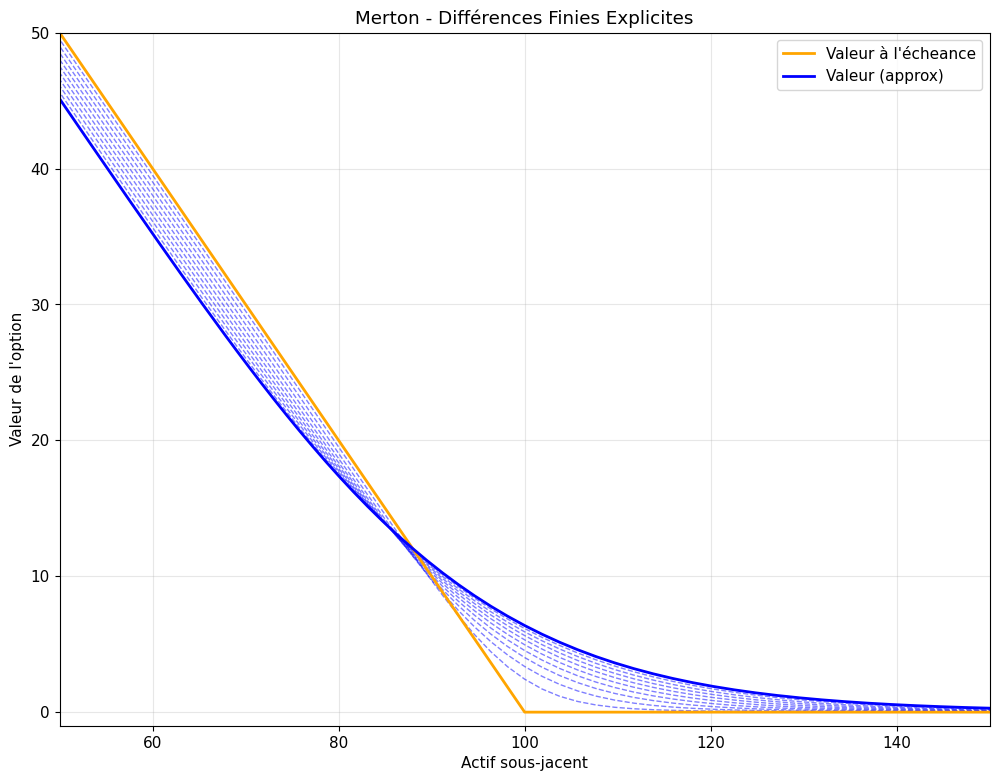

In [5]:
nom_methode = "Merton - Différences Finies Explicites"
nom_fichier = "merton_solution.png"

# Mapping des variables pour correspondre à votre snippet
x = S_values           # L'axe des abscisses (Prix de l'actif)
J = N                  # Nombre d'itérations temporelles
U0 = u_matrix[0, :]    # Condition initiale (Payoff à maturité)

plt.figure(figsize=(12,9))

# Boucle d'affichage (Simule l'évolution temporelle)
for j in range(J):

    # Dans notre code, Uj est déjà calculé dans la matrice.
    # Uj représente le prix de l'option au pas de temps j
    Uj = u_matrix[j, :]

    # visualisation de la solution approchee (toutes les 200 itérations pour ne pas surcharger)
    if (j + 1) % 200 == 0:
        plt.plot(x, Uj, color='blue', linestyle='dashed', linewidth=1, alpha=0.5)

# --- Réglages de la visualisation ---

# U_final correspond à la dernière ligne de notre matrice (t=0, aujourd'hui)
U_final = u_matrix[-1, :]

valin,  = plt.plot(x, U0,      color='orange', linestyle='solid', linewidth=2)
valfin, = plt.plot(x, U_final, color='blue',   linestyle='solid', linewidth=2)

plt.xlabel("Actif sous-jacent")
plt.ylabel("Valeur de l'option")

# AJUSTEMENT IMPORTANT : Zoom sur la zone d'intérêt (autour du Strike 100)
# (0,3) est trop petit pour un prix d'actif de 100
plt.xlim((50., 150.))
plt.ylim((-1, 50)) # Pour bien voir le payoff

plt.legend([valin, valfin], ["Valeur à l'écheance", "Valeur (approx)"])

plt.title(nom_methode)
plt.grid(True)
# plt.savefig(nom_fichier) # Décommentez pour sauvegarder
plt.show()

## 5. Formules analytiques : Black–Scholes et Merton et comparaison

On compare le schéma explicite avec :

- la formule de **Black–Scholes** pour un put européen (cas sans sauts),
- la formule de **Merton** pour le modèle avec sauts lognormaux.

---

**Put de Black–Scholes**

Pour un put de strike $K$, taux $r$, volatilité $\sigma$ et maturité $\tau$ :

$$
P_{\text{BS}}(S,K,r,\sigma,\tau)
= K e^{-r\tau} N(-d_2) - S N(-d_1),
$$
avec
$$
d_1 = \frac{\ln(S/K) + (r + \tfrac12\sigma^2)\tau}{\sigma\sqrt{\tau}},
\qquad
d_2 = d_1 - \sigma\sqrt{\tau}.
$$

---
**Put de Merton**

On note $\tau = T - t$, et
$$
\kappa := \mathbb{E}[\eta - 1] = e^{\mu + \tfrac12 \gamma^2} - 1.
$$

La formule de prix du put de Merton est :
$$
P_{\text{Merton}}(t,s)
=
e^{-r\tau}
\sum_{n \ge 0}
e^{-\lambda \tau}
\frac{(\lambda \tau)^n}{n!}
\, e^{r_n \tau}\,
V_{\text{BS}}(t, s_n, K, r_n, \sigma_n),
$$

avec :
$$
r_n
= r - \lambda\big(e^{\mu + \tfrac12\gamma^2} - 1\big)
  + \frac{n\mu}{t},
$$
$$
\sigma_n
= \sqrt{\sigma^2 + \frac{n\gamma^2}{t}},
\qquad
s_n = s\,e^{\tfrac12 n\gamma^2}.
$$

Ici $V_{\text{BS}}$ est la formule de Black–Scholes (put) avec paramètres $(r_n,\sigma_n)$
et sous-jacent $s_n$.



---


### 5.1 Put de Black–Scholes et Put de Merton

In [6]:
def bs_put_price(S, K, r, sigma, tau):
    if tau <= 0:
        return max(K - S, 0)

    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma*np.sqrt(tau)

    return K * np.exp(-r*tau) * norm.cdf(-d2) - S * norm.cdf(-d1)


# -------------------------
#  Merton Closed Form
# -------------------------
def merton_put_price(S, K, T, r, sigma, lam, mu, gamma, N_max=50):
    """
    Formule analytique de Merton pour un put européen.
    Version EXACTE de l'énoncé : r_n, sigma_n, s_n définis avec /t (t = T ici)
    """
    price = 0.0
    t = T   #

    # expectation E[η - 1]
    kappa = np.exp(mu + 0.5*gamma**2) - 1

    for n in range(N_max+1):

        # Poids de la loi de Poisson
        poisson_weight = np.exp(-lam*t) * (lam*t)**n / mt.factorial(n)

        # Paramètres
        r_n     = r - lam*kappa + (n*mu)/t
        sigma_n = np.sqrt(sigma**2 + (n*gamma**2)/t)
        s_n     = S * np.exp(n*gamma**2/2)

        # Prix Black-Scholes
        bs_n = bs_put_price(s_n, K, r_n, sigma_n, t)

        price += poisson_weight * bs_n

    return price

### 5.2 Comparaison numérique (PIDE) vs formule de Merton

In [7]:
def compare_with_merton_once(
    S0, K, T, r, sigma, lam, mu, gamma,
    M, N, P_width=10,
    N_max_merton=50,
    title="Comparaison schéma explicite / Merton analytique"
):
    """
    1) Résout la PIDE de Merton avec ton schéma explicite DFC.
    2) Calcule la formule analytique de Merton sur la même grille S.
    3) Affiche num vs analytique + erreurs.
    """

    # 1. Résolution numérique
    x_grid, u_matrix = merton_solver_explicit_all_steps(
        S0, K, T, r, sigma, lam, mu, gamma, M, N, P_width=P_width
    )
    S_values = K * np.exp(x_grid)
    U_final = u_matrix[-1, :]   # t=0 (aujourd'hui) : dernière ligne

    # 2. Prix de Merton analytique
    V_merton = merton_put_price(
        S_values, K, T, r, sigma, lam, mu, gamma,
        N_max=N_max_merton
    )

    # 3. (optionnel) Prix BS sans sauts pour comparaison
    V_bs = bs_put_price(S_values, K, r, sigma, T)

    # 4. Erreurs
    error = U_final - V_merton
    err_inf = np.max(np.abs(error))
    err_L2  = np.sqrt(np.sum(error**2))

    print(f"Paramètres numériques : M = {M}, N = {N}, P_width = {P_width}")
    print(f"||e||_inf (num - Merton) = {err_inf:.4e}")
    print(f"||e||_2   (num - Merton) = {err_L2:.4e}")

    # 5. Plot comparaison
    plt.figure(figsize=(10, 6))
    plt.plot(S_values, V_merton, 'k-',  linewidth=2, label="Merton analytique")
    plt.plot(S_values, U_final,  'b--', linewidth=2, label="Numérique (PIDE)")
    plt.plot(S_values, V_bs,     'g:',  linewidth=1.5, label="Black–Scholes (sans sauts)")

    plt.xlabel("S")
    plt.ylabel("Prix du put")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.xlim(50, 150)
    plt.ylim(-1, 50)
    plt.show()

    return S_values, U_final, V_merton, err_inf, err_L2


Paramètres numériques : M = 150, N = 2000, P_width = 10
||e||_inf (num - Merton) = 6.3151e-01
||e||_2   (num - Merton) = 4.8468e+00


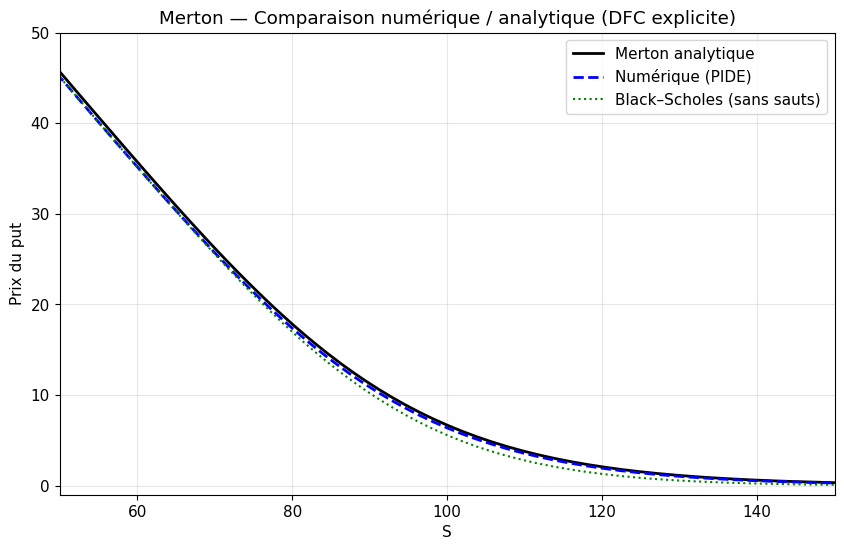

In [8]:
S_vals, U_num, U_mert, err_inf, err_L2 = compare_with_merton_once(
    S0, K, T, r, sigma, lam, mu, gamma,
    M, N, P_width=10,
    N_max_merton=50,
    title="Merton — Comparaison numérique / analytique (DFC explicite)"
)


### 5.3 Étude de convergence en temps et en espace

In [9]:
# -------------------------------------------------------------------
# 1) Construction d'une solution de référence numérique (fine grille)
# -------------------------------------------------------------------
def build_reference_solution_merton(
    S0, K, T, r, sigma, lam, mu, gamma,
    M_ref=300, N_ref=4000, P_width=10
):
    """
    Construit une solution de référence numérique sur une grille fine
    (M_ref, N_ref) pour le modèle de Merton avec TON schéma DFC.

    Retourne :
        S_ref : grille des prix (S)
        U_ref : solution numérique finale (t = 0) sur cette grille
    """
    print(">>> Construction de la solution de référence numérique...")
    x_ref, u_ref_mat = merton_solver_explicit_all_steps(
        S0, K, T, r, sigma, lam, mu, gamma,
        M_ref, N_ref, P_width=P_width
    )
    S_ref = K * np.exp(x_ref)
    U_ref = u_ref_mat[-1, :]   # t = 0 (aujourd'hui)

    print(f"Référence numérique construite avec M_ref={M_ref}, N_ref={N_ref}")
    return S_ref, U_ref


# -------------------------------------------------------------------
# 2) Étude de convergence (espace + temps) par rapport à la référence
# -------------------------------------------------------------------
def study_convergence_merton_numeric_ref(
    S0, K, T, r, sigma, lam, mu, gamma,
    M_values=(60, 90, 120, 150),
    N_values=(500, 1000, 2000, 4000),
    P_width=10,
    M_ref=300,
    N_ref=4000,
    save_prefix=None
):
    """
    Étude de convergence pour TON schéma explicite (DFC), en utilisant
    une SOLUTION NUMÉRIQUE DE RÉFÉRENCE sur grille fine (M_ref, N_ref).

    - Convergence en espace :
        N = N_ref fixé, M varie dans M_values.
        On compare U_final(M, N_ref) à la référence U_ref interpolée
        sur la grille en S correspondante.

    - Convergence en temps :
        M = M_ref fixé, N varie dans N_values.
        On compare U_final(M_ref, N) à la même U_ref (même grille en S).
    """

    # =========================
    # 0) Référence numérique
    # =========================
    S_ref, U_ref = build_reference_solution_merton(
        S0, K, T, r, sigma, lam, mu, gamma,
        M_ref=M_ref, N_ref=N_ref, P_width=P_width
    )

    # =========================
    # 1) Convergence en espace
    # =========================
    hs = []
    errs_space = []

    print("\nConvergence en espace (N = N_ref fixé) :")
    for M_test in M_values:
        # Résolution avec M_test, N_ref
        x_grid, u_matrix = merton_solver_explicit_all_steps(
            S0, K, T, r, sigma, lam, mu, gamma,
            M_test, N_ref, P_width=P_width
        )
        S_vals = K * np.exp(x_grid)
        U_final = u_matrix[-1, :]

        # Interpolation de la référence sur cette grille S_vals
        U_ref_interp = np.interp(S_vals, S_ref, U_ref)

        # Pas d'espace h
        dx = (x_grid[-1] - x_grid[0]) / M_test
        err_inf = np.max(np.abs(U_final - U_ref_interp))

        hs.append(dx)
        errs_space.append(err_inf)

        print(f"  M = {M_test:4d}, h = {dx:.3e}, err_inf = {err_inf:.3e}")

    hs = np.array(hs)
    errs_space = np.array(errs_space)

    # Estimation de l'ordre : log(err) ~ a + p log(h)
    # On enlève les éventuels err=0 pour éviter log(0)
    mask_space = errs_space > 0
    if np.sum(mask_space) >= 2:
        slope_space, intercept_space = np.polyfit(
            np.log(hs[mask_space]),
            np.log(errs_space[mask_space]),
            1
        )
        order_space = slope_space   # pas de signe moins ici
    else:
        slope_space, intercept_space, order_space = np.nan, np.nan, np.nan

    print(f"\nOrdre de convergence en espace (approx) : {order_space:.3f}")

    # =========================
    # 2) Convergence en temps
    # =========================
    ks = []
    errs_time = []

    print("\nConvergence en temps (M = M_ref fixé) :")
    for N_test in N_values:
        x_grid, u_matrix = merton_solver_explicit_all_steps(
            S0, K, T, r, sigma, lam, mu, gamma,
            M_ref, N_test, P_width=P_width
        )
        S_vals = K * np.exp(x_grid)
        U_final = u_matrix[-1, :]

        # La référence est sur la même grille S_ref (M_ref fixé)
        # On vérifie que S_vals == S_ref (juste au cas où)
        if not np.allclose(S_vals, S_ref):
            # Sécurité : interpolation si jamais ça ne matche pas
            U_ref_on_this_grid = np.interp(S_vals, S_ref, U_ref)
        else:
            U_ref_on_this_grid = U_ref

        dt = T / N_test
        err_inf = np.max(np.abs(U_final - U_ref_on_this_grid))

        ks.append(dt)
        errs_time.append(err_inf)

        print(f"  N = {N_test:4d}, k = {dt:.3e}, err_inf = {err_inf:.3e}")

    ks = np.array(ks)
    errs_time = np.array(errs_time)

    # Estimation de l'ordre : log(err) ~ a + q log(k)
    mask_time = errs_time > 0
    if np.sum(mask_time) >= 2:
        slope_time, intercept_time = np.polyfit(
            np.log(ks[mask_time]),
            np.log(errs_time[mask_time]),
            1
        )
        order_time = slope_time
    else:
        slope_time, intercept_time, order_time = np.nan, np.nan, np.nan

    print(f"\nOrdre de convergence en temps (approx) : {order_time:.3f}")

    # =========================
    # 3) Sauvegarde éventuelle
    # =========================
    if save_prefix is not None:
        data_space = np.column_stack([hs, errs_space])
        np.savetxt(
            f"{save_prefix}_space_numeric_ref.csv",
            data_space, delimiter=",",
            header="h,err_inf", comments=''
        )
        data_time = np.column_stack([ks, errs_time])
        np.savetxt(
            f"{save_prefix}_time_numeric_ref.csv",
            data_time, delimiter=",",
            header="k,err_inf", comments=''
        )
        print(
            f"\nRésultats sauvegardés dans "
            f"{save_prefix}_space_numeric_ref.csv et "
            f"{save_prefix}_time_numeric_ref.csv"
        )

    # =========================
    # 4) Figures log-log
    # =========================
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # --- Espace ---
    ax = axes[0]
    # Pour éviter log(0) sur le plot, on remplace les 0 par un tout petit epsilon
    errs_space_plot = errs_space.copy()
    eps_space = errs_space_plot[errs_space_plot > 0].min() * 0.5 if np.any(errs_space_plot > 0) else 1e-16
    errs_space_plot[errs_space_plot == 0] = eps_space

    ax.loglog(hs, errs_space_plot, 'o-', label="Erreur numérique")
    if np.isfinite(order_space):
        h_fit = np.linspace(hs.min(), hs.max(), 100)
        err_fit_space = np.exp(intercept_space + slope_space * np.log(h_fit))
        ax.loglog(h_fit, err_fit_space, '--', label=f"Fit (ordre ≈ {order_space:.2f})")

    ax.invert_xaxis()
    ax.set_xlabel("h")
    ax.set_ylabel("||e||_inf")
    ax.set_title("Convergence en espace (réf. numérique)")
    ax.grid(True, which="both")
    ax.legend()

    # --- Temps ---
    ax = axes[1]
    errs_time_plot = errs_time.copy()
    eps_time = errs_time_plot[errs_time_plot > 0].min() * 0.5 if np.any(errs_time_plot > 0) else 1e-16
    errs_time_plot[errs_time_plot == 0] = eps_time

    ax.loglog(ks, errs_time_plot, 's--', label="Erreur numérique")
    if np.isfinite(order_time):
        k_fit = np.linspace(ks.min(), ks.max(), 100)
        err_fit_time = np.exp(intercept_time + slope_time * np.log(k_fit))
        ax.loglog(k_fit, err_fit_time, ':', label=f"Fit (ordre ≈ {order_time:.2f})")

    ax.invert_xaxis()
    ax.set_xlabel("k")
    ax.set_ylabel("||e||_inf")
    ax.set_title("Convergence en temps (réf. numérique)")
    ax.grid(True, which="both")
    ax.legend()

    fig.tight_layout()
    plt.show()

    return hs, errs_space, ks, errs_time, order_space, order_time


>>> Construction de la solution de référence numérique...
Référence numérique construite avec M_ref=300, N_ref=4000

Convergence en espace (N = N_ref fixé) :
  M =   60, h = 4.621e-02, err_inf = 4.165e-02
  M =   90, h = 3.081e-02, err_inf = 1.916e-02
  M =  120, h = 2.310e-02, err_inf = 1.091e-02
  M =  150, h = 1.848e-02, err_inf = 5.217e-03

Ordre de convergence en espace (approx) : 2.204

Convergence en temps (M = M_ref fixé) :
  N =  500, k = 2.000e-03, err_inf = 1.918e-03
  N = 1000, k = 1.000e-03, err_inf = 8.221e-04
  N = 2000, k = 5.000e-04, err_inf = 2.740e-04
  N = 4000, k = 2.500e-04, err_inf = 0.000e+00

Ordre de convergence en temps (approx) : 1.404


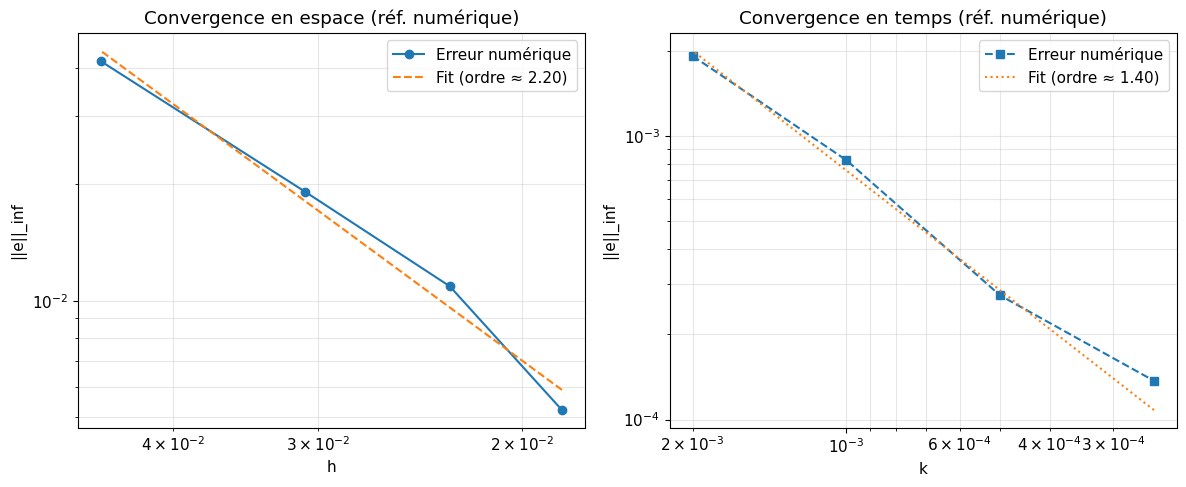

In [10]:
hs, errs_space, ks, errs_time, order_space, order_time = study_convergence_merton_numeric_ref(
    S0, K, T, r, sigma, lam, mu, gamma,
    M_values=(60, 90, 120, 150),
    N_values=(500, 1000, 2000, 4000),
    P_width=10,
    M_ref=300,    # ref en espace
    N_ref=4000,   # ref en temps
    save_prefix=None
)


## 6. Schéma Euler implicite / Crank-Nicolson

### 6.1 Euler implicite

In [11]:
# --- Schéma Implicite ---

def merton_implicit_scheme(
    S0, K, T, r, sigma, lam, mu, gamma,
    M, N, P_width=10
):
    """
    Schéma d'Euler implicite pur
    """


    # 1. Grille
    S_max = S0 * 4.0
    S_min = S0 / 4.0
    X_max = np.log(S_max / K)
    X_min = np.log(S_min / K)
    dx = (X_max - X_min) / M
    dt = T / N

    x_grid = np.linspace(X_min, X_max, M + 1)
    S_values = K * np.exp(x_grid)

    # 2. Paramètres Merton
    kappa = np.exp(mu + 0.5 * gamma**2) - 1.0
    nu = r - lam * kappa - 0.5 * sigma**2

    # 3. Coefficients pour la matrice implicite
    coeff_diff = sigma**2 / (2 * dx**2)
    coeff_conv = nu / (2 * dx)

    # Coefficients pour la matrice (I - dt*L)
    val_lower = -dt * (coeff_diff - coeff_conv)      # u_{i-1}
    val_diag  = 1 - dt * (-2 * coeff_diff - (r + lam))  # u_i
    val_upper = -dt * (coeff_diff + coeff_conv)      # u_{i+1}

    # Construction de la matrice creuse (points intérieurs seulement)
    dim = M - 1
    diags = [
        val_lower * np.ones(dim-1),  # sous-diagonale
        val_diag * np.ones(dim),     # diagonale principale
        val_upper * np.ones(dim-1)   # sur-diagonale
    ]

    A_implicit = sparse.diags(diags, offsets=[-1, 0, 1], format="csc")

    # Pré-factorisation LU
    solver = splu(A_implicit)

    # 4. Pré-calcul des poids pour l'intégrale
    P = int(np.ceil((P_width * gamma) / dx))
    m_indices = np.arange(-P, P + 1)
    y_vals = m_indices * dx
    eta_vals = np.exp(y_vals)

    kernel = g_eta(eta_vals, mu, gamma) * eta_vals * dx * lam * dt

    # 5. Condition initiale
    u = payoff_put(S_values, K)
    u_matrix = np.zeros((N + 1, M + 1))
    u_matrix[0, :] = u

    # 6. Boucle temporelle
    for n in range(N):
        tau_curr = n * dt
        tau_next = (n + 1) * dt

        # --- Terme intégral (explicite) ---
        u_extended = np.zeros(M + 1 + 2 * P)
        u_extended[P : P + M + 1] = u

        # Remplissage des points fantômes
        for k in range(P):
            x_ghost = X_min + (k - P) * dx
            u_extended[k] = u_left_boundary(tau_curr, x_ghost, K, r)

        # Points fantômes à droite
        u_extended[P + M + 1 :] = 0

        integral_term = np.zeros(dim)
        for i_int in range(dim):
            i_glob = i_int + 1
            start = P + i_glob - P
            end = P + i_glob + P + 1
            segment = u_extended[start:end]
            integral_term[i_int] = np.sum(segment * kernel)

        # --- Construction du vecteur droit ---
        u_inner = u[1:M]  # Points intérieurs actuels
        rhs_vec = u_inner + integral_term

        # --- Ajout des conditions aux limites ---
        bc_left_next = u_left_boundary(tau_next, X_min, K, r)
        bc_right_next = u_right_boundary(tau_next, X_max)

        # Influence des bords sur le système
        rhs_vec[0] += -val_lower * bc_left_next
        rhs_vec[-1] += -val_upper * bc_right_next

        # --- Résolution du système ---
        u_next_inner = solver.solve(rhs_vec)

        # Reconstruction du vecteur complet
        u_new = np.zeros_like(u)
        u_new[0] = bc_left_next
        u_new[M] = bc_right_next
        u_new[1:M] = u_next_inner

        u = u_new
        u_matrix[n + 1, :] = u

        if n % 20 == 0:
            idx_S0 = np.argmin(np.abs(S_values - S0))


    return x_grid, u_matrix, S_values


### 6.2 Crank - Nilcolson

In [12]:
# --- Schéma Crank-Nicolson ---

def merton_crank_nicolson_scheme(
    S0, K, T, r, sigma, lam, mu, gamma,
    M, N, P_width=10
):
    """
    Schéma de Crank-Nicolson pur
    """


    # 1. Grille
    S_max = S0 * 4.0
    S_min = S0 / 4.0
    X_max = np.log(S_max / K)
    X_min = np.log(S_min / K)
    dx = (X_max - X_min) / M
    dt = T / N

    x_grid = np.linspace(X_min, X_max, M + 1)
    S_values = K * np.exp(x_grid)

    # 2. Paramètres Merton
    kappa = np.exp(mu + 0.5 * gamma**2) - 1.0
    nu = r - lam * kappa - 0.5 * sigma**2

    # 3. Coefficients pour Crank-Nicolson
    coeff_diff = sigma**2 / (2 * dx**2)
    coeff_conv = nu / (2 * dx)

    # Coefficients pour la partie implicite (I - 0.5*dt*L)
    val_lower_imp = -0.5 * dt * (coeff_diff - coeff_conv)      # u_{i-1}^{n+1}
    val_diag_imp  = 1 - 0.5 * dt * (-2 * coeff_diff - (r + lam))  # u_i^{n+1}
    val_upper_imp = -0.5 * dt * (coeff_diff + coeff_conv)      # u_{i+1}^{n+1}

    # Coefficients pour la partie explicite (I + 0.5*dt*L)
    val_lower_exp = 0.5 * dt * (coeff_diff - coeff_conv)       # u_{i-1}^n
    val_diag_exp  = 1 + 0.5 * dt * (-2 * coeff_diff - (r + lam))   # u_i^n
    val_upper_exp = 0.5 * dt * (coeff_diff + coeff_conv)       # u_{i+1}^n

    # Construction de la matrice implicite
    dim = M - 1
    diags_imp = [
        val_lower_imp * np.ones(dim-1),
        val_diag_imp * np.ones(dim),
        val_upper_imp * np.ones(dim-1)
    ]

    A_implicit = sparse.diags(diags_imp, offsets=[-1, 0, 1], format="csc")

    # Construction de la matrice explicite
    diags_exp = [
        val_lower_exp * np.ones(dim-1),
        val_diag_exp * np.ones(dim),
        val_upper_exp * np.ones(dim-1)
    ]

    A_explicit = sparse.diags(diags_exp, offsets=[-1, 0, 1], format="csr")

    # Pré-factorisation LU
    solver = splu(A_implicit)

    # 4. Pré-calcul des poids pour l'intégrale
    P = int(np.ceil((P_width * gamma) / dx))
    m_indices = np.arange(-P, P + 1)
    y_vals = m_indices * dx
    eta_vals = np.exp(y_vals)

    kernel = g_eta(eta_vals, mu, gamma) * eta_vals * dx * lam * dt

    # 5. Condition initiale
    u = payoff_put(S_values, K)
    u_matrix = np.zeros((N + 1, M + 1))
    u_matrix[0, :] = u

    # 6. Boucle temporelle
    for n in range(N):
        tau_curr = n * dt
        tau_next = (n + 1) * dt

        # --- Terme intégral (explicite) ---
        u_extended = np.zeros(M + 1 + 2 * P)
        u_extended[P : P + M + 1] = u

        # Remplissage des points fantômes
        for k in range(P):
            x_ghost = X_min + (k - P) * dx
            u_extended[k] = u_left_boundary(tau_curr, x_ghost, K, r)

        u_extended[P + M + 1 :] = 0

        integral_term = np.zeros(dim)
        for i_int in range(dim):
            i_glob = i_int + 1
            start = P + i_glob - P
            end = P + i_glob + P + 1
            segment = u_extended[start:end]
            integral_term[i_int] = np.sum(segment * kernel)

        # --- Construction du vecteur droit ---
        u_inner = u[1:M]  # Points intérieurs actuels

        # Partie explicite de la diffusion
        rhs_vec = A_explicit.dot(u_inner) + integral_term

        # --- Ajout des conditions aux limites ---
        bc_left_curr = u_left_boundary(tau_curr, X_min, K, r)
        bc_right_curr = u_right_boundary(tau_curr, X_max)
        bc_left_next = u_left_boundary(tau_next, X_min, K, r)
        bc_right_next = u_right_boundary(tau_next, X_max)

        # Influence des bords sur les matrices
        rhs_vec[0] += (-val_lower_imp * bc_left_next +
                       val_lower_exp * bc_left_curr)
        rhs_vec[-1] += (-val_upper_imp * bc_right_next +
                        val_upper_exp * bc_right_curr)

        # --- Résolution du système ---
        u_next_inner = solver.solve(rhs_vec)

        # Reconstruction du vecteur complet
        u_new = np.zeros_like(u)
        u_new[0] = bc_left_next
        u_new[M] = bc_right_next
        u_new[1:M] = u_next_inner

        u = u_new
        u_matrix[n + 1, :] = u

        if n % 20 == 0:
            idx_S0 = np.argmin(np.abs(S_values - S0))


    return x_grid, u_matrix, S_values


### 6.3 Dispatcher des trois solveurs

In [13]:
SCHEME_LABELS = {
    "explicit": "Explicite DFC",
    "implicit": "Implicite (Euler backward)",
    "crank_nicolson": "Crank–Nicolson"
}


def merton_solver_scheme(
    S0, K, T, r, sigma, lam, mu, gamma,
    M, N, P_width=10,
    scheme="explicit"
):
    """
    Dispatcher simple :
      - scheme = "explicit"        -> merton_solver_explicit_all_steps
      - scheme = "implicit"        -> merton_implicit_scheme
      - scheme = "crank_nicolson"  -> merton_crank_nicolson_scheme

    Retourne toujours :
      x_grid, u_matrix, S_values
    """
    scheme = scheme.lower()
    if scheme == "explicit":
        x_grid, u_matrix = merton_solver_explicit_all_steps(
            S0, K, T, r, sigma, lam, mu, gamma, M, N, P_width=P_width
        )
        S_values = K * np.exp(x_grid)

    elif scheme == "implicit":
        x_grid, u_matrix, S_values = merton_implicit_scheme(
            S0, K, T, r, sigma, lam, mu, gamma, M, N, P_width=P_width
        )

    elif scheme == "crank_nicolson":
        x_grid, u_matrix, S_values = merton_crank_nicolson_scheme(
            S0, K, T, r, sigma, lam, mu, gamma, M, N, P_width=P_width
        )

    else:
        raise ValueError(f"Schéma inconnu : {scheme}")

    return x_grid, u_matrix, S_values


### 6.4 Simulation numérique : comparaison des 3 schémas

In [14]:
def plot_time_evolution_scheme(
    S0, K, T, r, sigma, lam, mu, gamma,
    M, N, P_width=10,
    scheme="explicit"
):
    """
    Reprend exactement le style de ta visualisation 4.4
    mais pour un schéma donné (explicit / implicit / crank_nicolson).
    """
    label_scheme = SCHEME_LABELS.get(scheme, scheme)

    # Résolution pour le schéma choisi
    x_grid, u_matrix, S_values = merton_solver_scheme(
        S0, K, T, r, sigma, lam, mu, gamma,
        M, N, P_width=P_width,
        scheme=scheme
    )

    x = S_values
    J = N
    U0 = u_matrix[0, :]
    U_final = u_matrix[-1, :]

    plt.figure(figsize=(12, 9))

    for j in range(J):
        Uj = u_matrix[j, :]
        # Même logique que ton code : affichage non surchargé
        if (j + 1) % 200 == 0:
            plt.plot(x, Uj, color='blue', linestyle='dashed', linewidth=1, alpha=0.5)

    valin,  = plt.plot(x, U0,      color='orange', linestyle='solid', linewidth=2)
    valfin, = plt.plot(x, U_final, color='blue',   linestyle='solid', linewidth=2)

    plt.xlabel("Actif sous-jacent")
    plt.ylabel("Valeur de l'option")
    plt.xlim((50., 150.))
    plt.ylim((-1, 50))

    plt.legend([valin, valfin],
               ["Valeur à l'échéance", f"Valeur (approx) – {label_scheme}"])

    plt.title(f"Merton - Différences finies ({label_scheme})")
    plt.grid(True)
    plt.show()

    return x_grid, u_matrix, S_values

Simulation numérique : évolution temporelle des 3 schémas

--- Schéma Explicite DFC ---


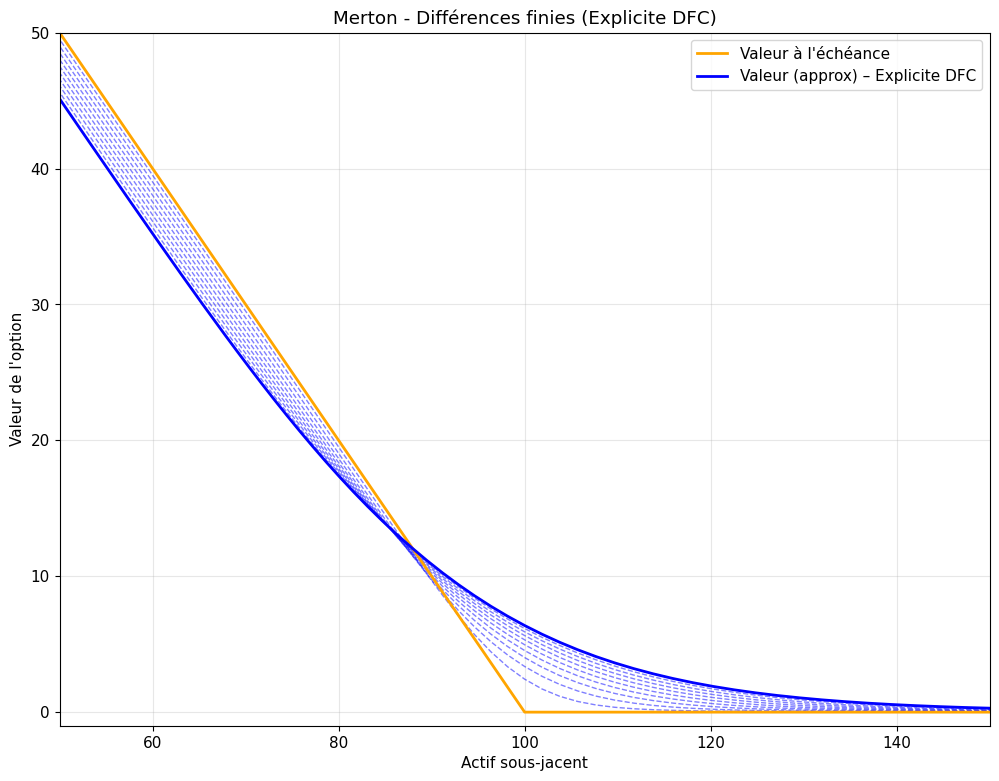

--- Schéma Implicite (Euler backward) ---


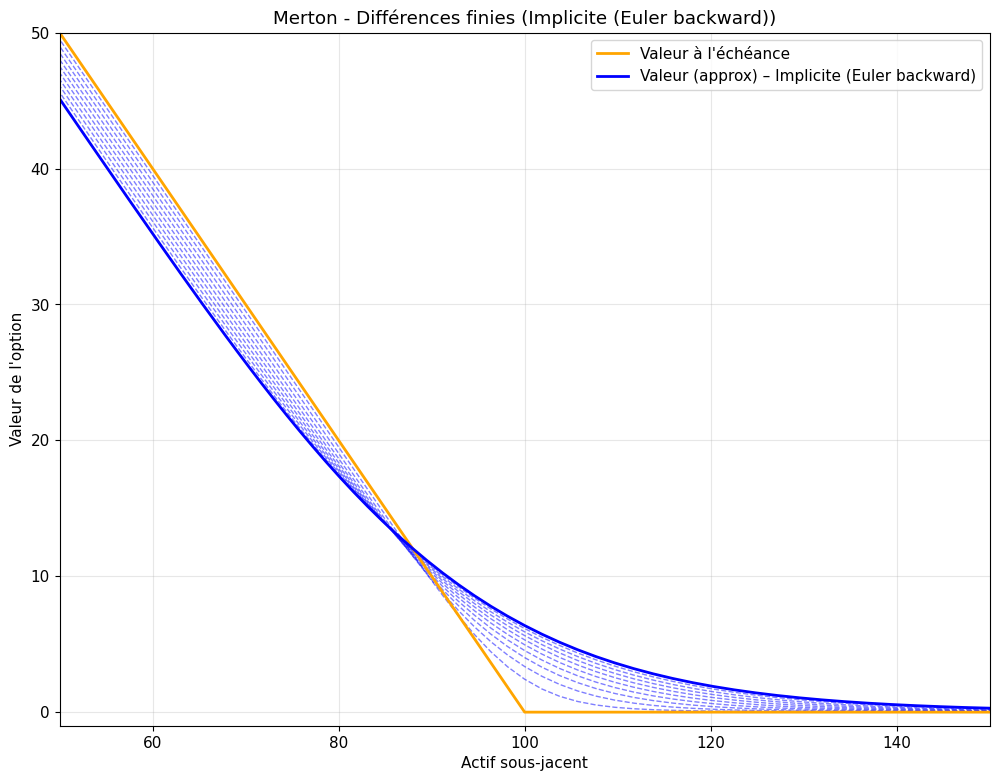

--- Schéma Crank–Nicolson ---


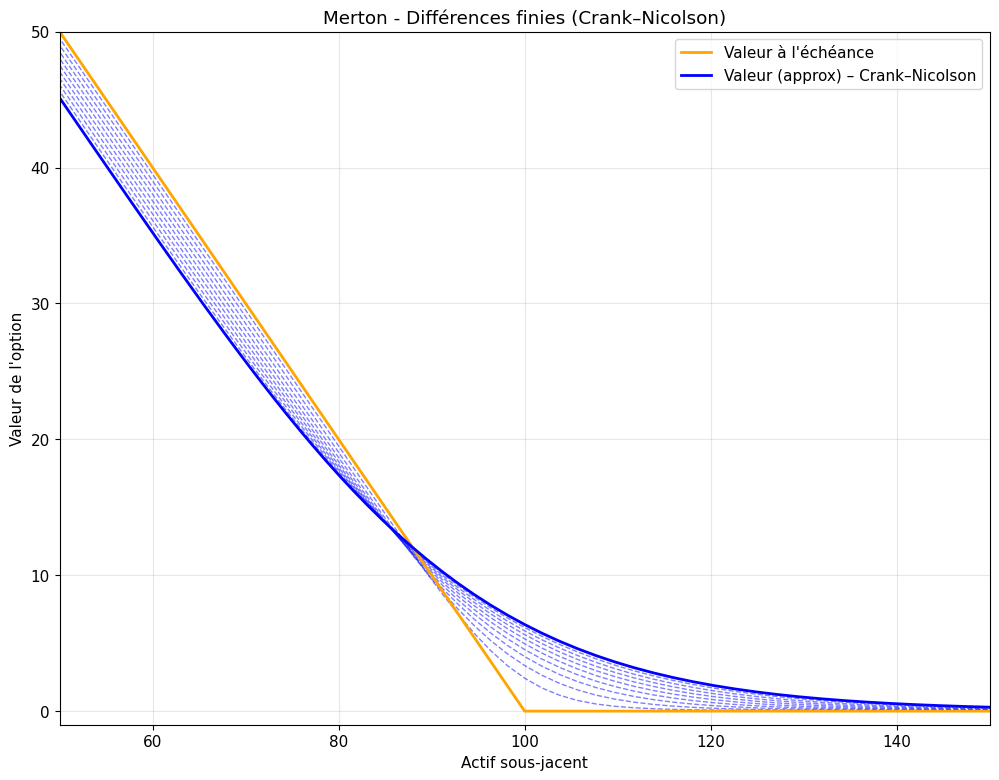

In [15]:
print("Simulation numérique : évolution temporelle des 3 schémas\n")
for sch in ["explicit", "implicit", "crank_nicolson"]:
    print(f"--- Schéma {SCHEME_LABELS[sch]} ---")
    _ = plot_time_evolution_scheme(
        S0, K, T, r, sigma, lam, mu, gamma,
        M, N, P_width=10,
        scheme=sch
    )


### 6.5 Comparaison avec la solution analytique de Merton

In [16]:
def compare_three_schemes_with_merton(
    S0, K, T, r, sigma, lam, mu, gamma,
    M, N, P_width=10,
    N_max_merton=50,
    title="Comparaison des trois schémas / Merton analytique"
):
    """
    Calcule la solution numérique pour les 3 schémas
    et les compare, sur un seul graphe, à :

      - Merton analytique
      - Black–Scholes (sans sauts)

    Affiche aussi ||e||_inf et ||e||_2 pour chaque schéma.
    """
    schemes = ["explicit", "implicit", "crank_nicolson"]

    # On calcule d'abord la solution "référence" analytique Merton sur la grille explicite
    x_exp, u_exp, S_values = merton_solver_scheme(
        S0, K, T, r, sigma, lam, mu, gamma,
        M, N, P_width=P_width,
        scheme="explicit"
    )
    U_exp_final = u_exp[-1, :]

    V_merton = merton_put_price(
        S_values, K, T, r, sigma, lam, mu, gamma,
        N_max=N_max_merton
    )
    V_bs = np.array([bs_put_price(S, K, r, sigma, T) for S in S_values])

    # On stocke les solutions finales pour tous les schémas
    U_final_dict = {"explicit": U_exp_final}
    err_inf_dict = {}
    err_L2_dict = {}

    print("\n>>> Comparaison numérique vs Merton analytique\n")
    print(f"Paramètres numériques : M = {M}, N = {N}, P_width = {P_width}\n")

    # Explicite déjà calculé
    error_exp = U_exp_final - V_merton
    err_inf_dict["explicit"] = np.max(np.abs(error_exp))
    err_L2_dict["explicit"] = np.sqrt(np.sum(error_exp**2))

    print(f"[{SCHEME_LABELS['explicit']}] ||e||_inf = {err_inf_dict['explicit']:.4e} "
          f"||e||_2 = {err_L2_dict['explicit']:.4e}")

    # Implicite / Crank–Nicolson
    for sch in ["implicit", "crank_nicolson"]:
        x_sch, u_sch, S_values_sch = merton_solver_scheme(
            S0, K, T, r, sigma, lam, mu, gamma,
            M, N, P_width=P_width,
            scheme=sch
        )
        U_sch_final = u_sch[-1, :]

        # On suppose la même grille spatiale ; sinon, on pourrait interpoler.
        # Ici M, S_min, S_max sont identiques -> grilles identiques en pratique.
        U_final_dict[sch] = U_sch_final

        error = U_sch_final - V_merton
        err_inf = np.max(np.abs(error))
        err_L2 = np.sqrt(np.sum(error**2))

        err_inf_dict[sch] = err_inf
        err_L2_dict[sch] = err_L2

        print(f"[{SCHEME_LABELS[sch]}]   ||e||_inf = {err_inf:.4e} "
              f"||e||_2 = {err_L2:.4e}")

    # --- Plot sur un seul graphe ---
    plt.figure(figsize=(10, 6))

    # Merton analytique
    plt.plot(S_values, V_merton, 'k-', linewidth=2, label="Merton analytique")

    # Trois schémas
    plt.plot(S_values, U_final_dict["explicit"], 'b--', linewidth=2,
             label=f"Numérique – {SCHEME_LABELS['explicit']}")
    plt.plot(S_values, U_final_dict["implicit"], 'r-.', linewidth=2,
             label=f"Numérique – {SCHEME_LABELS['implicit']}")
    plt.plot(S_values, U_final_dict["crank_nicolson"], 'g:', linewidth=2,
             label=f"Numérique – {SCHEME_LABELS['crank_nicolson']}")

    # Black–Scholes (sans sauts)
    plt.plot(S_values, V_bs, color='gray', linestyle='dotted', linewidth=1.5,
             label="Black–Scholes (sans sauts)")

    plt.xlabel("S")
    plt.ylabel("Prix du put")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.xlim(50, 150)
    plt.ylim(-1, 50)
    plt.show()

    return S_values, V_merton, V_bs, U_final_dict, err_inf_dict, err_L2_dict





>>> Comparaison numérique vs Merton analytique

Paramètres numériques : M = 150, N = 2000, P_width = 10

[Explicite DFC] ||e||_inf = 6.3151e-01 ||e||_2 = 4.8468e+00
[Implicite (Euler backward)]   ||e||_inf = 6.3151e-01 ||e||_2 = 4.8376e+00
[Crank–Nicolson]   ||e||_inf = 6.3151e-01 ||e||_2 = 4.8420e+00


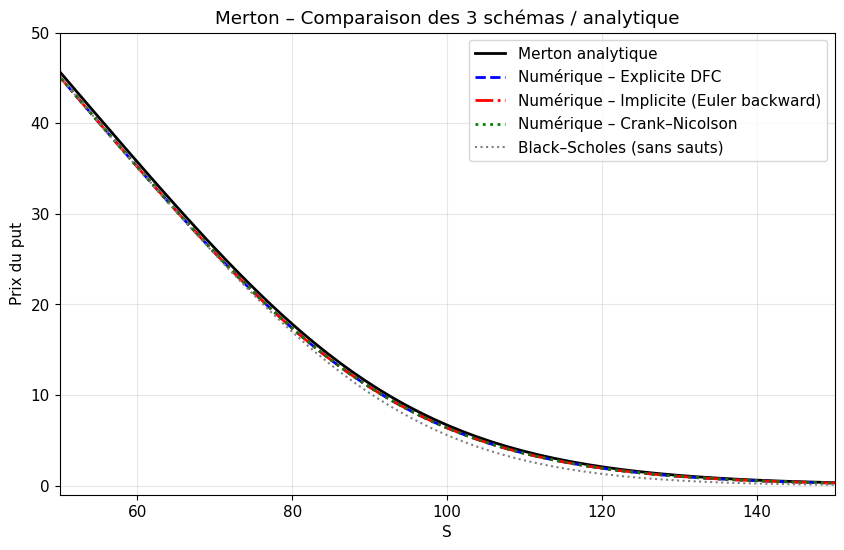

In [17]:
# Appel de la comparaison pour tes paramètres courants
S_vals, V_mert_ref, V_bs_ref, U_final_dict, err_inf_dict, err_L2_dict = compare_three_schemes_with_merton(
    S0, K, T, r, sigma, lam, mu, gamma,
    M, N, P_width=10,
    N_max_merton=50,
    title="Merton – Comparaison des 3 schémas / analytique"
)

### 6.6 Étude de convergence en temps et en espace

In [18]:
# ============================================================
# 0) Dispatcher pour appeler le bon schéma (EXP, IMP, CN)
# ============================================================

def merton_solve_one_step_scheme(
    scheme,
    S0, K, T, r, sigma, lam, mu, gamma,
    M, N, P_width=10
):

    scheme = scheme.lower()

    if scheme == "explicit":
        # Ton schéma DFC explicite existant
        x_grid, u_matrix = merton_solver_explicit_all_steps(
            S0, K, T, r, sigma, lam, mu, gamma,
            M, N, P_width=P_width
        )
        S_vals = K * np.exp(x_grid)
        U_final = u_matrix[-1, :]

    elif scheme == "implicit":
        # Ton schéma implicite (signature inchangée)
        x_grid, u_matrix, S_vals = merton_implicit_scheme(
            S0, K, T, r, sigma, lam, mu, gamma,
            M, N, P_width=P_width
        )
        U_final = u_matrix[-1, :]

    elif scheme in {"crank-nicolson", "cn"}:
        # Ton schéma Crank–Nicolson (signature inchangée)
        x_grid, u_matrix, S_vals = merton_crank_nicolson_scheme(
            S0, K, T, r, sigma, lam, mu, gamma,
            M, N, P_width=P_width
        )
        U_final = u_matrix[-1, :]

    else:
        raise ValueError(f"Schéma inconnu : {scheme} (attendu : 'explicit', 'implicit', 'crank-nicolson')")

    return S_vals, U_final


# -------------------------------------------------------------------
# 1) Construction d'une solution de référence numérique (fine grille)
# -------------------------------------------------------------------

def build_reference_solution_merton(
    scheme,
    S0, K, T, r, sigma, lam, mu, gamma,
    M_ref=300, N_ref=4000, P_width=10
):
    """
    Construit une solution de référence numérique sur une grille fine
    (M_ref, N_ref) pour le modèle de Merton, avec le schéma choisi.

    scheme ∈ {"explicit", "implicit", "crank-nicolson"}

    Retourne :
        S_ref : grille des prix (S)
        U_ref : solution numérique finale (t = 0) sur cette grille
    """
    print(f">>> Construction de la solution de référence numérique ({scheme})...")

    S_ref, U_ref = merton_solve_one_step_scheme(
        scheme,
        S0, K, T, r, sigma, lam, mu, gamma,
        M_ref, N_ref, P_width=P_width
    )

    print(f"Référence numérique construite avec M_ref={M_ref}, N_ref={N_ref}")
    return S_ref, U_ref


# -------------------------------------------------------------------
# 2) Étude de convergence (espace + temps) par rapport à la référence
# -------------------------------------------------------------------

def study_convergence_merton_numeric_ref(
    scheme,
    S0, K, T, r, sigma, lam, mu, gamma,
    M_values=(60, 90, 120, 150),
    N_values=(500, 1000, 2000, 4000),
    P_width=10,
    M_ref=300,
    N_ref=4000,
    save_prefix=None
):
    """
    Étude de convergence pour le schéma 'scheme' (explicit / implicit / crank-nicolson),
    en utilisant une SOLUTION NUMÉRIQUE DE RÉFÉRENCE sur grille fine (M_ref, N_ref).

    - Convergence en espace :
        N = N_ref fixé, M varie dans M_values.
        On compare U_final(M, N_ref) à la référence U_ref interpolée
        sur la grille en S correspondante.

    - Convergence en temps :
        M = M_ref fixé, N varie dans N_values.
        On compare U_final(M_ref, N) à la même U_ref (même grille en S).
    """

    scheme = scheme.lower()

    # =========================
    # 0) Référence numérique
    # =========================
    S_ref, U_ref = build_reference_solution_merton(
        scheme,
        S0, K, T, r, sigma, lam, mu, gamma,
        M_ref=M_ref, N_ref=N_ref, P_width=P_width
    )

    # =========================
    # 1) Convergence en espace
    # =========================
    hs = []
    errs_space = []

    print(f"\nConvergence en espace (N = N_ref fixé) — schéma {scheme} :")
    for M_test in M_values:
        # Résolution avec M_test, N_ref
        S_vals, U_final = merton_solve_one_step_scheme(
            scheme,
            S0, K, T, r, sigma, lam, mu, gamma,
            M_test, N_ref, P_width=P_width
        )

        # Interpolation de la référence sur cette grille S_vals
        U_ref_interp = np.interp(S_vals, S_ref, U_ref)

        # Pas d'espace h (en x)
        X_min = np.log((S0 / 4.0) / K)
        X_max = np.log((S0 * 4.0) / K)
        dx = (X_max - X_min) / M_test

        err_inf = np.max(np.abs(U_final - U_ref_interp))

        hs.append(dx)
        errs_space.append(err_inf)

        print(f"  M = {M_test:4d}, h = {dx:.3e}, err_inf = {err_inf:.3e}")

    hs = np.array(hs)
    errs_space = np.array(errs_space)

    # Estimation de l'ordre : log(err) ~ a + p log(h)
    mask_space = errs_space > 0
    if np.sum(mask_space) >= 2:
        slope_space, intercept_space = np.polyfit(
            np.log(hs[mask_space]),
            np.log(errs_space[mask_space]),
            1
        )
        order_space = slope_space   # même logique que ta version
    else:
        slope_space, intercept_space, order_space = np.nan, np.nan, np.nan

    print(f"\nOrdre de convergence en espace (approx) : {order_space:.3f}")

    # =========================
    # 2) Convergence en temps
    # =========================
    ks = []
    errs_time = []

    print(f"\nConvergence en temps (M = M_ref fixé) — schéma {scheme} :")
    for N_test in N_values:
        S_vals, U_final = merton_solve_one_step_scheme(
            scheme,
            S0, K, T, r, sigma, lam, mu, gamma,
            M_ref, N_test, P_width=P_width
        )

        # La référence est sur la grille S_ref (M_ref fixé)
        if not np.allclose(S_vals, S_ref):
            U_ref_on_this_grid = np.interp(S_vals, S_ref, U_ref)
        else:
            U_ref_on_this_grid = U_ref

        dt = T / N_test
        err_inf = np.max(np.abs(U_final - U_ref_on_this_grid))

        ks.append(dt)
        errs_time.append(err_inf)

        print(f"  N = {N_test:4d}, k = {dt:.3e}, err_inf = {err_inf:.3e}")

    ks = np.array(ks)
    errs_time = np.array(errs_time)

    # Estimation de l'ordre : log(err) ~ a + q log(k)
    mask_time = errs_time > 0
    if np.sum(mask_time) >= 2:
        slope_time, intercept_time = np.polyfit(
            np.log(ks[mask_time]),
            np.log(errs_time[mask_time]),
            1
        )
        order_time = slope_time
    else:
        slope_time, intercept_time, order_time = np.nan, np.nan, np.nan

    print(f"\nOrdre de convergence en temps (approx) : {order_time:.3f}")

    # =========================
    # 3) Sauvegarde éventuelle
    # =========================
    if save_prefix is not None:
        # On ajoute le nom du schéma dans le prefix pour éviter d'écraser
        pref = f"{save_prefix}_{scheme}"

        data_space = np.column_stack([hs, errs_space])
        np.savetxt(
            f"{pref}_space_numeric_ref.csv",
            data_space, delimiter=",",
            header="h,err_inf", comments=''
        )
        data_time = np.column_stack([ks, errs_time])
        np.savetxt(
            f"{pref}_time_numeric_ref.csv",
            data_time, delimiter=",",
            header="k,err_inf", comments=''
        )
        print(
            f"\nRésultats sauvegardés dans "
            f"{pref}_space_numeric_ref.csv et "
            f"{pref}_time_numeric_ref.csv"
        )

    # =========================
    # 4) Figures log-log
    # =========================
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # --- Espace ---
    ax = axes[0]
    errs_space_plot = errs_space.copy()
    if np.any(errs_space_plot > 0):
        eps_space = errs_space_plot[errs_space_plot > 0].min() * 0.5
    else:
        eps_space = 1e-16
    errs_space_plot[errs_space_plot == 0] = eps_space

    ax.loglog(hs, errs_space_plot, 'o-', label="Erreur numérique")
    if np.isfinite(order_space):
        h_fit = np.linspace(hs.min(), hs.max(), 100)
        err_fit_space = np.exp(intercept_space + slope_space * np.log(h_fit))
        ax.loglog(h_fit, err_fit_space, '--', label=f"Fit (ordre ≈ {order_space:.2f})")

    ax.invert_xaxis()
    ax.set_xlabel("h")
    ax.set_ylabel("||e||_inf")
    ax.set_title(f"Convergence en espace (réf. numérique, {scheme})")
    ax.grid(True, which="both")
    ax.legend()

    # --- Temps ---
    ax = axes[1]
    errs_time_plot = errs_time.copy()
    if np.any(errs_time_plot > 0):
        eps_time = errs_time_plot[errs_time_plot > 0].min() * 0.5
    else:
        eps_time = 1e-16
    errs_time_plot[errs_time_plot == 0] = eps_time

    ax.loglog(ks, errs_time_plot, 's--', label="Erreur numérique")
    if np.isfinite(order_time):
        k_fit = np.linspace(ks.min(), ks.max(), 100)
        err_fit_time = np.exp(intercept_time + slope_time * np.log(k_fit))
        ax.loglog(k_fit, err_fit_time, ':', label=f"Fit (ordre ≈ {order_time:.2f})")

    ax.invert_xaxis()
    ax.set_xlabel("k")
    ax.set_ylabel("||e||_inf")
    ax.set_title(f"Convergence en temps (réf. numérique, {scheme})")
    ax.grid(True, which="both")
    ax.legend()

    fig.tight_layout()
    plt.show()

    return hs, errs_space, ks, errs_time, order_space, order_time


In [19]:
# Étude de convergence pour les trois schémas, même style d'affichage

"""print("\n================= SCHÉMA EXPLICITE (DFC) =================\n")
hs_exp, errsp_exp, ks_exp, errst_exp, ordsp_exp, ordst_exp = study_convergence_merton_numeric_ref(
    "explicit",
    S0, K, T, r, sigma, lam, mu, gamma,
    M_values=(60, 90, 120, 150),
    N_values=(500, 1000, 2000, 4000),
    P_width=10,
    M_ref=300,
    N_ref=4000,
    save_prefix=None
)

print("\n================= SCHÉMA IMPLICITE =================\n")
hs_imp, errsp_imp, ks_imp, errst_imp, ordsp_imp, ordst_imp = study_convergence_merton_numeric_ref(
    "implicit",
    S0, K, T, r, sigma, lam, mu, gamma,
    M_values=(60, 90, 120, 150),
    N_values=(500, 1000, 2000, 4000),
    P_width=10,
    M_ref=300,
    N_ref=4000,
    save_prefix=None
)

print("\n================= SCHÉMA CRANK–NICOLSON =================\n")
hs_cn, errsp_cn, ks_cn, errst_cn, ordsp_cn, ordst_cn = study_convergence_merton_numeric_ref(
    "crank-nicolson",
    S0, K, T, r, sigma, lam, mu, gamma,
    M_values=(60, 90, 120, 150),
    N_values=(500, 1000, 2000, 4000),
    P_width=10,
    M_ref=300,
    N_ref=4000,
    save_prefix=None
)
"""

'print("\n================= SCHÉMA EXPLICITE (DFC) =================\n")\nhs_exp, errsp_exp, ks_exp, errst_exp, ordsp_exp, ordst_exp = study_convergence_merton_numeric_ref(\n    "explicit",\n    S0, K, T, r, sigma, lam, mu, gamma,\n    M_values=(60, 90, 120, 150),\n    N_values=(500, 1000, 2000, 4000),\n    P_width=10,\n    M_ref=300,\n    N_ref=4000,\n    save_prefix=None\n)\n\nprint("\n================= SCHÉMA IMPLICITE =================\n")\nhs_imp, errsp_imp, ks_imp, errst_imp, ordsp_imp, ordst_imp = study_convergence_merton_numeric_ref(\n    "implicit",\n    S0, K, T, r, sigma, lam, mu, gamma,\n    M_values=(60, 90, 120, 150),\n    N_values=(500, 1000, 2000, 4000),\n    P_width=10,\n    M_ref=300,\n    N_ref=4000,\n    save_prefix=None\n)\n\nprint("\n================= SCHÉMA CRANK–NICOLSON =================\n")\nhs_cn, errsp_cn, ks_cn, errst_cn, ordsp_cn, ordst_cn = study_convergence_merton_numeric_ref(\n    "crank-nicolson",\n    S0, K, T, r, sigma, lam, mu, gamma,\n    M_values=

In [20]:
def convergence_analysis(S0, K, T, r, sigma, lam, mu, gamma):
    """
    Analyse de convergence en temps et en espace
    """


    # Référence: solution très fine avec Crank-Nicolson (plus précis)

    M_ref, N_ref = 1000, 1000
    _, u_ref_cn, S_vals_ref = merton_crank_nicolson_scheme(
        S0, K, T, r, sigma, lam, mu, gamma, M_ref, N_ref, P_width=12
    )

    idx_atm = np.argmin(np.abs(S_vals_ref - S0))
    reference_value = u_ref_cn[-1, idx_atm]


    # Tests de convergence en espace (temps fixe)

    N_fixed = 500  # Temps fixe assez fin
    M_values = [100, 200, 300, 400, 500]

    spatial_errors_imp = []
    spatial_errors_cn = []

    for M in M_values:


        # Implicite
        _, u_imp, S_vals = merton_implicit_scheme(
            S0, K, T, r, sigma, lam, mu, gamma, M, N_fixed, P_width=10
        )

        idx_atm = np.argmin(np.abs(S_vals - S0))
        value_imp = u_imp[-1, idx_atm]
        error_imp = abs(value_imp - reference_value)
        spatial_errors_imp.append(error_imp)

        # Crank-Nicolson
        _, u_cn, _ = merton_crank_nicolson_scheme(
            S0, K, T, r, sigma, lam, mu, gamma, M, N_fixed, P_width=10
        )

        value_cn = u_cn[-1, idx_atm]
        error_cn = abs(value_cn - reference_value)
        spatial_errors_cn.append(error_cn)


    # Tests de convergence en temps (espace fixe)

    M_fixed = 500  # Espace fixe assez fin
    N_values = [100, 200, 300, 400, 500]

    temporal_errors_imp = []
    temporal_errors_cn = []

    for N in N_values:


        # Implicite
        _, u_imp, S_vals = merton_implicit_scheme(
            S0, K, T, r, sigma, lam, mu, gamma, M_fixed, N, P_width=10
        )

        idx_atm = np.argmin(np.abs(S_vals - S0))
        value_imp = u_imp[-1, idx_atm]
        error_imp = abs(value_imp - reference_value)
        temporal_errors_imp.append(error_imp)

        # Crank-Nicolson
        _, u_cn, _ = merton_crank_nicolson_scheme(
            S0, K, T, r, sigma, lam, mu, gamma, M_fixed, N, P_width=10
        )

        value_cn = u_cn[-1, idx_atm]
        error_cn = abs(value_cn - reference_value)
        temporal_errors_cn.append(error_cn)



    # Visualisation des résultats de convergence
    plt.figure(figsize=(14, 6))

    # Convergence en espace
    plt.subplot(1, 2, 1)
    dx_values = [1.0/M for M in M_values]

    plt.loglog(dx_values, spatial_errors_imp, 'bo-', label='Implicite', linewidth=3, markersize=8)
    plt.loglog(dx_values, spatial_errors_cn, 'ro-', label='Crank-Nicolson', linewidth=3, markersize=8)

    # Référence pour l'ordre de convergence
    order_1 = [spatial_errors_imp[0] * (dx/dx_values[0]) for dx in dx_values]
    order_2 = [spatial_errors_cn[0] * (dx/dx_values[0])**2 for dx in dx_values]
    plt.loglog(dx_values, order_1, 'k--', label='Ordre 1', alpha=0.5, linewidth=1)
    plt.loglog(dx_values, order_2, 'k:', label='Ordre 2', alpha=0.5, linewidth=1)

    plt.xlabel('Δx', fontsize=12)
    plt.ylabel('Erreur absolue', fontsize=12)
    plt.title('Convergence en espace\n(erreur à S0)', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)

    # Convergence en temps
    plt.subplot(1, 2, 2)
    dt_values = [T/N for N in N_values]

    plt.loglog(dt_values, temporal_errors_imp, 'bo-', label='Implicite', linewidth=3, markersize=8)
    plt.loglog(dt_values, temporal_errors_cn, 'ro-', label='Crank-Nicolson', linewidth=3, markersize=8)

    # Référence pour l'ordre de convergence
    order_1 = [temporal_errors_imp[0] * (dt/dt_values[0]) for dt in dt_values]
    order_2 = [temporal_errors_cn[0] * (dt/dt_values[0])**2 for dt in dt_values]
    plt.loglog(dt_values, order_1, 'k--', label='Ordre 1', alpha=0.5, linewidth=1)
    plt.loglog(dt_values, order_2, 'k:', label='Ordre 2', alpha=0.5, linewidth=1)

    plt.xlabel('Δt', fontsize=12)
    plt.ylabel('Erreur absolue', fontsize=12)
    plt.title('Convergence en temps\n(erreur à S0)', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Analyse détaillée des ordres de convergence


    def calculate_orders(errors, steps):
        orders = []
        for i in range(1, len(errors)):
            if errors[i-1] > 0 and errors[i] > 0:
                order = np.log(errors[i-1] / errors[i]) / np.log(steps[i] / steps[i-1])
                orders.append(order)
        return orders

    # Ordres de convergence spatiaux
    spatial_orders_imp = calculate_orders(spatial_errors_imp, dx_values)
    spatial_orders_cn = calculate_orders(spatial_errors_cn, dx_values)

    # Ordres de convergence temporels
    temporal_orders_imp = calculate_orders(temporal_errors_imp, dt_values)
    temporal_orders_cn = calculate_orders(temporal_errors_cn, dt_values)


    return {
        'spatial_errors_imp': spatial_errors_imp,
        'spatial_errors_cn': spatial_errors_cn,
        'temporal_errors_imp': temporal_errors_imp,
        'temporal_errors_cn': temporal_errors_cn,
        'spatial_orders_imp': spatial_orders_imp,
        'spatial_orders_cn': spatial_orders_cn,
        'temporal_orders_imp': temporal_orders_imp,
        'temporal_orders_cn': temporal_orders_cn
    }

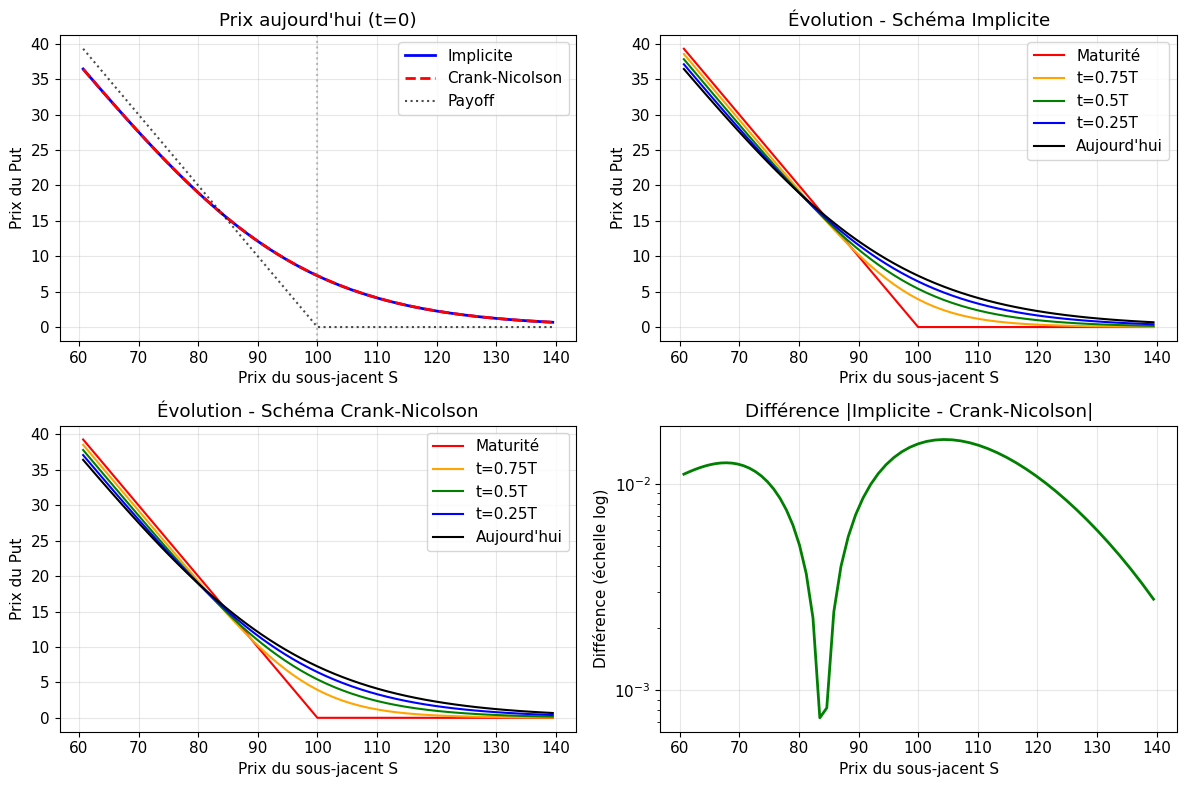

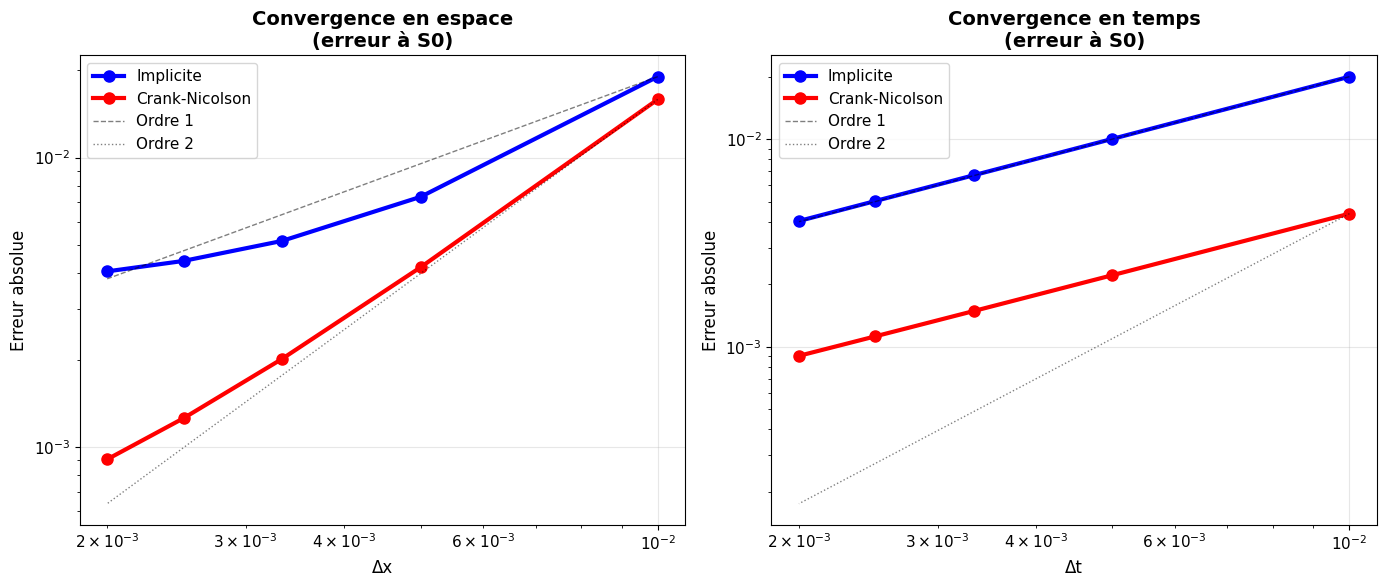

In [21]:
# --- Paramètres de simulation ---
S0, K = 100.0, 100.0
T = 1.0
r = 0.03
sigma = 0.2
lam = 0.5
mu = -0.1
gamma = 0.1
M = 200
N = 100



# --- Exécution Implicite ---
x_grid_imp, u_mat_imp, S_vals = merton_implicit_scheme(
    S0, K, T, r, sigma, lam, mu, gamma, M, N, P_width=8
)

# --- Exécution Crank-Nicolson ---
x_grid_cn, u_mat_cn, _ = merton_crank_nicolson_scheme(
    S0, K, T, r, sigma, lam, mu, gamma, M, N, P_width=8
)

# --- Visualisation ---
plt.figure(figsize=(12, 8))

# Graphique 1: Comparaison des prix aujourd'hui
plt.subplot(2, 2, 1)
mask = (S_vals > 60) & (S_vals < 140)

plt.plot(S_vals[mask], u_mat_imp[-1, :][mask], 'b-', label='Implicite', linewidth=2)
plt.plot(S_vals[mask], u_mat_cn[-1, :][mask], 'r--', label='Crank-Nicolson', linewidth=2)
plt.plot(S_vals[mask], payoff_put(S_vals[mask], K), 'k:', label='Payoff', alpha=0.7)

plt.title("Prix aujourd'hui (t=0)")
plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Prix du Put")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axvline(x=K, color='gray', linestyle=':', alpha=0.5)

# Graphique 2: Évolution temporelle - Implicite
plt.subplot(2, 2, 2)
time_points = [0, N//4, N//2, 3*N//4, N]
labels = ['Maturité', 't=0.75T', 't=0.5T', 't=0.25T', 'Aujourd\'hui']
colors = ['red', 'orange', 'green', 'blue', 'black']

for i, t_idx in enumerate(time_points):
    plt.plot(S_vals[mask], u_mat_imp[t_idx, :][mask],
             color=colors[i], label=labels[i], linewidth=1.5)

plt.title("Évolution - Schéma Implicite")
plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Prix du Put")
plt.legend()
plt.grid(True, alpha=0.3)

# Graphique 3: Évolution temporelle - Crank-Nicolson
plt.subplot(2, 2, 3)
for i, t_idx in enumerate(time_points):
    plt.plot(S_vals[mask], u_mat_cn[t_idx, :][mask],
             color=colors[i], label=labels[i], linewidth=1.5)

plt.title("Évolution - Schéma Crank-Nicolson")
plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Prix du Put")
plt.legend()
plt.grid(True, alpha=0.3)

# Graphique 4: Différence entre les méthodes
plt.subplot(2, 2, 4)
difference = np.abs(u_mat_imp[-1, :] - u_mat_cn[-1, :])
plt.semilogy(S_vals[mask], difference[mask], 'g-', linewidth=2)
plt.title("Différence |Implicite - Crank-Nicolson|")
plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Différence (échelle log)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Résultats numériques ---
idx_atm = np.argmin(np.abs(S_vals - S0))
idx_itm = np.argmin(np.abs(S_vals - 80))   # Put in-the-money
idx_otm = np.argmin(np.abs(S_vals - 120))  # Put out-of-the-money



for idx, label in [(idx_itm, "ITM (80)"), (idx_atm, "ATM (100)"), (idx_otm, "OTM (120)")]:
    S = S_vals[idx]
    imp = u_mat_imp[-1, idx]
    cn = u_mat_cn[-1, idx]
    diff = abs(imp - cn)



# --- Analyse de convergence ---
convergence_results = convergence_analysis(S0, K, T, r, sigma, lam, mu, gamma)